In [88]:
import unicodedata

def remover_acentos(texto):
    if isinstance(texto, str):
        return ''.join(
            c for c in unicodedata.normalize('NFKD', texto)
            if not unicodedata.combining(c)
        )
    return texto

In [3]:
import pandas as pd
import numpy as np
from datetime import date
import json
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import gaussian_kde
import seaborn as sns

import folium
import joypy
import altair as alt

In [2]:
import datetime

In [47]:
csv_date = datetime.datetime(2020,12,1)

In [51]:
csv_date >= datetime.datetime(2019,12,31)

False

In [53]:
csv_date < datetime.datetime(2022,7,1)

True

In [63]:
cols = ['a','b','Data_de_cadastro']

In [67]:
[*['c','d'],*list(set(cols) - set(df_traf.columns))]

['c', 'd', 'a', 'b']

In [73]:
with open(fr"C:\Users\rosan\Projeto\Disque100\src\utils\columns_rename.json", 'r', encoding='utf-8') as f:
    dict_rename = json.load(f)

In [74]:
dict_rename.keys()

dict_keys(['2011_2019', '2020_01_2022_01', '2022_02_2026_01', 'mlg'])

In [76]:
import pandas as pd
from pathlib import Path 
import os
import re
from typing import Optional

In [158]:
from pathlib import Path 
import datetime
import json
import numpy as np

project_path = Path().resolve()
data_path = fr'C:\Users\rosan\Projeto\Disque100\src\utils'

with open(fr'{data_path}\transformations.json', 'r', encoding='utf-8') as f:
    dict_transform = json.load(f)

with open(fr'{data_path}\colors.json', 'r', encoding='utf-8') as f:
    dict_color = json.load(f)

with open(fr'{data_path}\columns_rename.json', 'r', encoding='utf-8') as f:
    dict_rename = json.load(f)

with open(fr'{data_path}\columns_extraction.json', 'r', encoding='utf-8') as f:
    dict_get_columns = json.load(f)

with open(fr'{data_path}\years_extraction.json', 'r', encoding='utf-8') as f:
    dict_years = json.load(f)

def filter_dataset(df):
    terms = ['EXPLORACAO SEXUAL','EXPLORAÇÃO SEXUAL','TRÁFICO HUMANO','TRAFICO HUMANO','TRÁFICO SEXUAL','TRAFICO SEXUAL']
    try:
        df_filt = df[df['violacao'].str.contains('|'.join(terms))]
    except:
        df_filt = df[df['violacoes'].str.contains('|'.join(terms))]
    
    return df_filt

def rename_columns(df, type_extraction, period):
    if len(period) > 4:
        year = period.split("_")[0]
        semester = period.split("_")[1]
    else:
        year = period
        semester = "02"
    month = 6 if semester == "01" else 12
    date_csv = datetime.datetime(int(year), int(month), 1)
    if date_csv <= datetime.datetime(2019,12,31):
        rename_columns = dict_rename["2011_2019"]
    elif date_csv <=  datetime.datetime(2022,7,1):
        rename_columns = dict_rename["2020_01_2022_01"]
    else:
        rename_columns = dict_rename["2022_02_2026_01"]
    return df.rename(columns = rename_columns)

def columns_extraction(type_extraction):
    if type_extraction == "survival":
        columns = dict_get_columns["survival_analysis"]
    elif type_extraction == "mlg":
        columns = dict_get_columns["mlg"]
    else:
        columns = dict_get_columns["dashboard"]
    return columns

def get_columns(df, type_extraction):
    if type_extraction == "survival":
        columns = dict_get_columns["survival_analysis"]
    elif type_extraction == "mlg":
        columns = dict_get_columns["mlg"]
    else:
        columns = dict_get_columns["dashboard"]
    return df[columns]

def chech_year(df, type_extraction):
    if type_extraction == "survival":
        years = dict_years["survival_analysis"]
    elif type_extraction == "mlg":
        years = dict_years["mlg"]
    else:
        years = dict_years["dashboard"]
    missing_cols = set(columns_extraction(type_extraction)) - set(df.columns)
    print(f"falta colunas: {missing_cols}")
    for col in missing_cols:
        df[col] = np.nan
    return df

def transform_column(df, column):
    print(f'Termos que não estão no csv para a coluna: {column}')
    print(df[~df[column].isin(dict_transform[column])][column].unique())
    return df[column].map(dict_transform[column])

def get_date_csv_file(csv_name, transform:Optional[bool] = True):
    if "primeiro" in csv_name or "segundo" in csv_name:
        dict_sem = {
            "primeiro":"01",
            "segundo":"02"
        }
        pattern = re.compile("|".join(map(re.escape, dict_sem.keys())))
        semester = re.findall(pattern, csv_name)[0]
        year = re.findall(r'\d{4}', csv_name)[-1]

        return f'{year}_{dict_sem[semester]}'
    else:
        year = csv_name.split("-")[1].split(".")[0]
        return f'{year}'

In [172]:
from pathlib import Path

path = Path(
    r"C:\Users\rosan\Projeto\Dashboard-HT\src\data\in\disque100_dashboard_ajustado.csv"
)

print(path)
print(path.exists())
print(path.is_file())

C:\Users\rosan\Projeto\Dashboard-HT\src\data\in\disque100_dashboard_ajustado.csv
True
True


In [159]:
df_traf_total = pd.DataFrame(columns = cols)
years_errors = []

In [160]:
csv_date

'2021_01'

In [161]:
cols = columns_extraction("survival")

csv_date = get_date_csv_file(csv_name = "disque100-primeiro-semestre-2021.csv", transform = False)

df_disque100 = rename_columns(df = df_traf, type_extraction = "survival", period=csv_date)


In [162]:
df_disque100 = chech_year(df_disque100, "survival")
print("checou datas")

falta colunas: set()
checou datas


In [163]:
df_disque100_filt = df_disque100[cols]

In [164]:
df_disque100_filt = filter_dataset(df_disque100_filt)

In [165]:
df_disque100['Município_da_vítima']

0                      JACOBINA
1                      BRASÍLIA
2             MARECHAL FLORIANO
3                BELO HORIZONTE
4                       UBERABA
                  ...          
450413                  BACABAL
450414              CARAPICUÍBA
450415    FERRAZ DE VASCONCELOS
450416              CARAPICUÍBA
450417         FEIRA DE SANTANA
Name: Município_da_vítima, Length: 450418, dtype: str

In [166]:
df_disque100_filt.columns

Index(['Data_de_cadastro', 'Município_da_vítima', 'UF_da_vítima',
       'Gênero_da_vítima', 'Raça_Cor_da_vítima', 'Faixa_etária_da_vítima',
       'Gênero_do_suspeito', 'Faixa_etária_do_suspeito',
       'Relação_vítima_suspeito', 'Cenário_da_violação', 'violacao',
       'Início_das_violações'],
      dtype='str')

In [167]:
df_disque100_filt.head(2)

,Data_de_cadastro,Município_da_vítima,UF_da_vítima,Gênero_da_vítima,Raça_Cor_da_vítima,Faixa_etária_da_vítima,Gênero_do_suspeito,Faixa_etária_do_suspeito,Relação_vítima_suspeito,Cenário_da_violação,violacao,Início_das_violações
59,13/01/2021 23:04,CACIMBINHAS,AL,N/D,N/D,NaN,MASCULINO,55 A 59 ANOS,OUTROS,CASA DO SUSPEITO,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL,NÃO SE APLICA
118,05/01/2021 15:38,JUIZ DE FORA,MG,FEMININO,N/D,NaN,FEMININO,N/D,TIO (A),CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL,HÁ UM MÊS


In [168]:
df_traf_total.columns

Index(['Data_de_cadastro', 'Município_da_vítima', 'UF_da_vítima',
       'Gênero_da_vítima', 'Raça_Cor_da_vítima', 'Faixa_etária_da_vítima',
       'Gênero_do_suspeito', 'Faixa_etária_do_suspeito',
       'Relação_vítima_suspeito', 'Cenário_da_violação', 'violacao',
       'Início_das_violações'],
      dtype='str')

In [169]:
df_disque100_filt.columns

Index(['Data_de_cadastro', 'Município_da_vítima', 'UF_da_vítima',
       'Gênero_da_vítima', 'Raça_Cor_da_vítima', 'Faixa_etária_da_vítima',
       'Gênero_do_suspeito', 'Faixa_etária_do_suspeito',
       'Relação_vítima_suspeito', 'Cenário_da_violação', 'violacao',
       'Início_das_violações'],
      dtype='str')

In [170]:
set(df_disque100_filt.columns) - set(df_traf_total.columns)

set()

In [171]:
df_traf_total = pd.concat([df_traf_total, df_disque100_filt], axis=0)

In [140]:
for col in df_traf.columns:
    if 'unic' in col:
        print(col)

Município
sl_vitima_naturalizado_municipio
Município  da vítima
sl_suspeito_naturalizado_municipio
sl_suspeito_municipio


In [141]:
df_traf['Município  da vítima'].head(4)

0             JACOBINA
1             BRASÍLIA
2    MARECHAL FLORIANO
3       BELO HORIZONTE
Name: Município  da vítima, dtype: str

In [101]:
df_traf = pd.read_csv(r"C:\Users\rosan\Projeto\Disque100\src\data\in\disque100-primeiro-semestre-2021.csv",sep=";")
df_traf.head()

,hash,Data de cadastro,Canal de atendimento,Denúncia emergencial,Denunciante,Cenário da violação,País,UF,Município,Frequência,...,Grau de instrução do suspeito,Religião do suspeito,Raça\Cor do suspeito,Suspeito Etnia,Faixa de renda do suspeito,Vínculo Órgão\PJ do suspeito,sl_suspeito_ramo,suspeito_especificacao_etnia,vitima_especificacao_etnia,violacao
0,9f6859cabb6e7bb9d35246ebfe98c90d,02/01/2021 10:37,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,BA,JACOBINA,SEMANALMENTE,...,N/D,N/D,N/D,N/D,N/D,NaN,N/D,N/D,N/D,INTEGRIDADE>PSÍQUICA>INSUBSISTÊNCIA AFETIVA
1,1d267c09b9c0542ba81958b2907abcbf,15/01/2021 14:42,TELEFÔNICO,NÃO,ANÔNIMO,VIA PÚBLICA,BRASIL,DF,BRASÍLIA,DIARIAMENTE,...,N/D,N/D,N/D,N/D,N/D,NaN,N/D,N/D,N/D,INTEGRIDADE>FÍSICA>SITUAÇÃO DE RUA ou ABANDONO...
2,a02c68d0c8790d8e99c86d3aeb25a9fa,14/01/2021 12:15,TELEFÔNICO,NÃO,A PRÓPRIA VÍTIMA,CASA DA VÍTIMA,BRASIL,ES,MARECHAL FLORIANO,OCASIONALMENTE,...,N/D,N/D,BRANCA,N/D,N/D,NaN,N/D,N/D,N/D,INTEGRIDADE>PSÍQUICA>TORTURA PSÍQUICA
3,01535ebda2bb2c2957a57c1994ecf2eb,02/01/2021 21:21,TELEFÔNICO,RISCO IMINENTE DE MORTE DA VÍTIMA,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,MG,BELO HORIZONTE,DIARIAMENTE,...,ENSINO MÉDIO COMPLETO,N/D,BRANCA,N/D,ATÉ 1 SM,NaN,N/D,N/D,N/D,INTEGRIDADE>FÍSICA>LESÃO CORPORAL
4,ff837f385c8ae54ab068e1cac318d986,11/01/2021 10:33,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,MG,UBERABA,DIARIAMENTE,...,N/D,N/D,BRANCA,N/D,N/D,NaN,N/D,N/D,N/D,INTEGRIDADE>FÍSICA>SITUAÇÃO DE RUA ou ABANDONO...


In [102]:
df_traf.columns

Index(['hash', 'Data de cadastro', 'Canal de atendimento',
       'Denúncia emergencial', 'Denunciante', 'Cenário da violação', 'País',
       'UF', 'Município', 'Frequência', 'Início das violações',
       'sl_quantidade_vitimas', 'Grupo vulnerável', 'Motivação',
       'Relação vítima-suspeito', 'sl_vitima_cadastro', 'Gênero da vítima',
       'Orientação sexual da vítima', 'Faixa etária da vítima',
       'Nacionalidade da vítima', 'sl_vitima_naturalidade',
       'sl_vitima_naturalizado_uf', 'sl_vitima_naturalizado_municipio',
       'Deficiência da vítima', 'Doença rara da vítima',
       'Deficiência relacionada a doença rara ?', 'Vítima preso(a)',
       'País da vítima', 'UF da vítima', 'Município  da vítima',
       'Profissão da vítima', 'Grau de instrução da vítima',
       'Religião da vítima', 'Raça\Cor da vítima', 'Etnia da vítima',
       'Faixa de renda da vítima', 'Natureza Jurídica do Suspeito',
       'Gênero do suspeito', 'Orientação sexual do suspeito',
       'Fai

In [42]:
df_traf.columns

Index(['data_atendimento', 'tipo_atendimento', 'grupo_violacao',
       'sub_grupo_violacao', 'data_cenario', 'hora_cenario', 'cenario_local',
       'cenario_ocorrencia', 'relacao_demandante', 'relacao_suspeito',
       'vitima_cod_municipio', 'vitima_municipio', 'vitima_uf',
       'vitima_faixa_etaria', 'vitima_estado_civil', 'vitima_sexo',
       'vitima_escolaridade', 'vitima_identidade_genero', 'vitima_cor_raca',
       'vitima_orientacao_sexual', 'suspeito_pf_cod_municipio',
       'suspeito_pf_municipio', 'suspeito_pf_uf', 'suspeito_pf_faixa_etaria',
       'suspeito_pf_estado_civil', 'suspeito_pf_sexo',
       'suspeito_pf_escolaridade', 'suspeito_pf_identidade_genero',
       'suspeito_pf_cor_raca', 'suspeito_pf_orientacao_sexual',
       'suspeito_pj_cod_municipio', 'suspeito_pj_municipio', 'suspeito_pj_uf',
       'suspeito_pj_qualificacao_juridica', 'violacoes'],
      dtype='str')

In [31]:
terms = ['EXPLORACAO SEXUAL','EXPLORAÇÃO SEXUAL','TRÁFICO HUMANO','TRAFICO HUMANO','TRÁFICO SEXUAL','TRAFICO SEXUAL']

In [33]:
df_traf[df_traf['violacao'].str.contains('|'.join(termos))].shape

(5579, 14)

In [29]:
df_traf.shape

(99949, 14)

In [30]:
df_traf['violacao'].unique()

<StringArray>
[                                                                                                                                                                                                                                                                                                                                                                                                                                                                      'NEGLIGÊNCIA.NEGLIGÊNCIA EM AMPARO E RESPONSABILIZAÇÃO',
                                                                                                                                                                                                                                                                                                   'ABUSO FINANCEIRO E ECONÔMICO/ VIOLÊNCIA PATRIMONIAL.EXPROPRIAÇÃO/ APROPRIAÇÃO DE BENS;ABUSO FINANCEIRO E ECONÔMICO/ VIOLÊNCIA PATRIMONIAL.RETENÇÃO DE SALÁRIO/ BENS;NEGLIGÊNCIA.NEGLIG

In [2]:
df_traf = pd.read_csv(r"C:\Users\rosan\Projeto\Análise de Sobrevivência - HT\analise sobrev\disque100_todos.csv",sep=";")
df_traf.head()

C:\Users\rosan\AppData\Local\Temp\ipykernel_32316\2113205829.py:1: DtypeWarning: Columns (7: hash) have mixed types. Specify dtype option on import or set low_memory=False.
  df_traf = pd.read_csv(r"C:\Users\rosan\Projeto\Análise de Sobrevivência - HT\analise sobrev\disque100_todos.csv",sep=";")


,Unnamed: 0,Cenário_da_violação,Gênero_da_vítima,Faixa_etária_da_vítima,Gênero_do_suspeito,UF_da_vítima,Faixa_etária_do_suspeito,hash,Raça_Cor_da_vítima,Data_de_cadastro,violacao,Grau_de_instrução_da_vítima,Relação_vítima_suspeito,Município_da_vítima,Gênero_da_vítima_ajust,data,ano_mes,ano,semestre,ano_semestre
0,25,Casa,Feminino,18 a 24 anos,Feminino,PR,51 a 55 anos,140,Branca,2011-01-05 21:01:57.000,VIOLÊNCIA SEXUAL.EXPLORAÇÃO SEXUAL;TORTURA E O...,Ensino Médio completo,Mãe,Abatia ...,Feminino,2011-01-05,2011-01,2011,1,2011_1
1,26,Casa,Feminino,18 a 24 anos,Feminino,PR,N/D,141,Branca,2011-01-05 21:01:57.000,VIOLÊNCIA SEXUAL.EXPLORAÇÃO SEXUAL;VIOLÊNCIA P...,Ensino Médio completo,Amigo (a),Abatia ...,Feminino,2011-01-05,2011-01,2011,1,2011_1
2,37,Casa,Masculino,18 a 24 anos,Feminino,PR,N/D,210,Branca,2011-01-08 08:45:33.000,VIOLÊNCIA SEXUAL.EXPLORAÇÃO SEXUAL;VIOLÊNCIA S...,Ensino Médio completo,Mãe,Santa Isabel do Ivai ...,Masculino,2011-01-08,2011-01,2011,1,2011_1
3,40,Casa,Feminino,18 a 24 anos,Feminino,PR,31 a 35 anos,215,Branca,2011-01-08 10:55:15.000,VIOLÊNCIA SEXUAL.EXPLORAÇÃO SEXUAL;VIOLÊNCIA F...,Ensino Superior completo,Desconhecido(a),Santa Cruz de Monte Castelo ...,Feminino,2011-01-08,2011-01,2011,1,2011_1
4,51,Rua,Não informado,N/D,Feminino,PR,N/D,247,Branca,2011-01-09 16:10:39.000,VIOLÊNCIA SEXUAL.EXPLORAÇÃO SEXUAL;VIOLÊNCIA S...,Ensino Fundamental completo,Mãe,Santa Cruz de Monte Castelo ...,Não Informado,2011-01-09,2011-01,2011,1,2011_1


In [30]:
df_traf.shape

(103741, 20)

In [31]:
df_traf.columns

Index(['Unnamed: 0', 'Cenário_da_violação', 'Gênero_da_vítima',
       'Faixa_etária_da_vítima', 'Gênero_do_suspeito', 'UF_da_vítima',
       'Faixa_etária_do_suspeito', 'hash', 'Raça_Cor_da_vítima',
       'Data_de_cadastro', 'violacao', 'Grau_de_instrução_da_vítima',
       'Relação_vítima_suspeito', 'Município_da_vítima',
       'Gênero_da_vítima_ajust', 'data', 'ano_mes', 'ano', 'semestre',
       'ano_semestre'],
      dtype='str')

In [32]:
df_traf['data'].min()

'2011-01-05'

In [33]:
df_traf['data'].max()

'2025-12-31'

In [34]:
df_traf[['Município_da_vítima', 'hash']].groupby('Município_da_vítima', as_index=False).size().rename(columns={'size': 'count'})

,Município_da_vítima,count
0,(),144
1,1100015 | ALTA FLORESTA D'OESTE,1
2,1100023 | ARIQUEMES,1
3,1100049 | CACOAL,2
4,1100106 | GUAJARÁ-MIRIM,1
...,...,...
7390,ÁGUAS LINDAS DE GOIÁS,4
7391,ÁGUIA BRANCA,1
7392,ÁLVARES MACHADO,2
7393,ÁUREA,1


In [35]:
df_traf['Município_da_vítima'].unique()

<StringArray>
['Abatia                                        (PR)',
 'Santa Isabel do Ivai                          (PR)',
 'Santa Cruz de Monte Castelo                   (PR)',
 'Paranavai                                     (PR)',
 'Fortaleza                                     (CE)',
 'Belem                                         (PA)',
 'Rio de Janeiro                                (RJ)',
 'Nova Iguacu                                   (RJ)',
 'Pinheiro                                      (MA)',
 'Parnamirim                                    (RN)',
 ...
                           '3160603 | SANTO HIPÓLITO',
                            '3169307 | TRÊS CORAÇÕES',
                       '2908408 | CONCEIÇÃO DO COITÉ',
                                   '2604809 | CORTÊS',
                           '3136207 | JOÃO MONLEVADE',
                       '4212809 | BALNEÁRIO PIÇARRAS',
                                 '2303501 | CASCAVEL',
                              '3125705 | FELIX

In [36]:
df_traf[df_traf['Município_da_vítima'].isna()].shape

(56, 20)

In [52]:
df_traf = df_traf[~(
                    (df_traf['Município_da_vítima'].isna()) |
                    (df_traf['Município_da_vítima']==0) |
                    (df_traf['Município_da_vítima']=='0') |
                    (df_traf['UF_da_vítima'].isin(['N/D', 'DENUNCIANTE NÃO SOUBE INFORMAR','ATENDIMENTO INTERROMPIDO'])) |
                    (df_traf['UF_da_vítima'].isna())
                   )
]

In [53]:
df_traf.shape

(102015, 22)

In [54]:
df_traf['Município_da_vítima'] = df_traf['Município_da_vítima'].apply(lambda x: remover_acentos(x.upper().strip()))

In [69]:
nomes = []
for x in df_traf['Município_da_vítima']:
    if '(' in x:
        nomes.append(x.split('(')[0].strip())
    elif '|' in x:
        nomes.append(x.split('|')[1].strip())
    else:
        nomes.append(x.strip())

In [70]:
estados = [x.upper().strip() for x in df_traf['UF_da_vítima']]
estados[:10]

['PR', 'PR', 'PR', 'PR', 'PR', 'PR', 'CE', 'PA', 'RJ', 'RJ']

In [71]:
df_traf['estado_vitima'] = estados
df_traf['municipio_vitima'] = nomes

In [72]:
df_traf[['estado_vitima','municipio_vitima']].head()

,estado_vitima,municipio_vitima
0,PR,ABATIA
1,PR,ABATIA
2,PR,SANTA ISABEL DO IVAI
3,PR,SANTA CRUZ DE MONTE CASTELO
4,PR,SANTA CRUZ DE MONTE CASTELO


In [73]:
df_traf['municipio_vitima'].unique()

<StringArray>
[                     'ABATIA',        'SANTA ISABEL DO IVAI',
 'SANTA CRUZ DE MONTE CASTELO',                   'PARANAVAI',
                   'FORTALEZA',                       'BELEM',
              'RIO DE JANEIRO',                 'NOVA IGUACU',
                    'PINHEIRO',                  'PARNAMIRIM',
 ...
             'VARJAO DE MINAS',                      'JAICOS',
                 'ALPINOPOLIS',               'BENEDITO NOVO',
                       'GRACA',       'CAMPOS NOVOS PAULISTA',
                   'JAGUARIPE',        'SAO JOSE DO BARREIRO',
                     'PINDOBA',                 'FELIXLANDIA']
Length: 4000, dtype: str

In [ ]:
colunas = ['municipio_vitima','estado_vitima','hash']
df_traf['municipio_vitima']

In [16]:
df_traf_munic = pd.read_csv(r"C:\Users\rosan\Projeto\Análise de Sobrevivência - HT\analise sobrev\disque100_ate_2019.csv",sep=",")
df_traf_munic.head()

C:\Users\rosan\AppData\Local\Temp\ipykernel_32316\3776313816.py:1: DtypeWarning: Columns (4: sub_grupo_violacao) have mixed types. Specify dtype option on import or set low_memory=False.
  df_traf_munic = pd.read_csv(r"C:\Users\rosan\Projeto\Análise de Sobrevivência - HT\analise sobrev\disque100_ate_2019.csv",sep=",")


,Unnamed: 0,data_atendimento,tipo_atendimento,grupo_violacao,sub_grupo_violacao,data_cenario,hora_cenario,cenario_local,cenario_ocorrencia,relacao_demandante,...,suspeito_pf_sexo,suspeito_pf_escolaridade,suspeito_pf_identidade_genero,suspeito_pf_cor_raca,suspeito_pf_orientacao_sexual,suspeito_pj_cod_municipio,suspeito_pj_municipio,suspeito_pj_uf,suspeito_pj_qualificacao_juridica,violacoes
0,8,2011-01-01 03:00:53.000,CENTRAL DE ATENDIMENTO,LGBT,NaN,2011-01-01 00:00:00.0000000,02:40,Rua,Não informado,Própria vítima,...,Masculino,Ensino Fundamental incompleto,Masculina,Branca,Heterossexual,NaN,(),N/D,N/D,DISCRIMINAÇÃO.POR ORIENTAÇÃO SEXUAL;VIOLÊNCIA ...
1,9,2011-01-01 03:13:02.000,CENTRAL DE ATENDIMENTO,LGBT,NaN,2010-12-31 00:00:00.0000000,23:40,Rua,Diariamente,Própria vítima,...,Feminino,Ensino Fundamental incompleto,Feminina,Parda,Heterossexual,NaN,(),N/D,N/D,DISCRIMINAÇÃO.POR ORIENTAÇÃO SEXUAL;VIOLÊNCIA ...
2,22,2011-01-01 18:46:50.000,CENTRAL DE ATENDIMENTO,LGBT,NaN,NaN,N/D,Casa,Não informado,Companheiro (a),...,Masculino,Ensino Fundamental incompleto,Masculina,Preta,Heterossexual,NaN,(),N/D,N/D,VIOLÊNCIA SEXUAL.ABUSO SEXUAL;VIOLÊNCIA FÍSICA...
3,27,2011-01-02 08:40:34.000,CENTRAL DE ATENDIMENTO,População situação de rua,NaN,2011-01-01 00:00:00.0000000,22:00,Rua,Não informado,Esposa,...,Masculino,Não informado,Não informado,Branca,Não informado,NaN,(),N/D,N/D,VIOLÊNCIA SEXUAL.ABUSO SEXUAL
4,28,2011-01-02 08:40:34.000,CENTRAL DE ATENDIMENTO,População situação de rua,NaN,2011-01-01 00:00:00.0000000,22:00,Rua,Não informado,Esposa,...,Masculino,Não informado,Não informado,Parda,Não informado,NaN,(),N/D,N/D,VIOLÊNCIA SEXUAL.ABUSO SEXUAL


In [17]:
df_traf_munic.shape

(341646, 36)

In [18]:
df_traf_munic['violacoes'].unique()

<StringArray>
[                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             'DISCRIMINAÇÃO.POR ORIENTAÇÃO SEXUAL;VIOLÊNCIA FÍSICA.LESÃO CORPORAL',
                                                                                                                                                                                                                                                                                                                                                                                                                     

In [19]:
termos = ['EXPLORACAO SEXUAL','EXPLORAÇÃO SEXUAL','TRÁFICO HUMANO','TRAFICO HUMANO','TRÁFICO SEXUAL','TRAFICO SEXUAL']
df_traf_munic[df_traf_munic['violacoes'].str.contains('|'.join(termos))].shape

(85663, 36)

In [20]:
df_traf_munic = df_traf_munic[df_traf_munic['violacoes'].str.contains('|'.join(termos))]

In [21]:
df_traf_munic.columns

Index(['Unnamed: 0', 'data_atendimento', 'tipo_atendimento', 'grupo_violacao',
       'sub_grupo_violacao', 'data_cenario', 'hora_cenario', 'cenario_local',
       'cenario_ocorrencia', 'relacao_demandante', 'relacao_suspeito',
       'vitima_cod_municipio', 'vitima_municipio', 'vitima_uf',
       'vitima_faixa_etaria', 'vitima_estado_civil', 'vitima_sexo',
       'vitima_escolaridade', 'vitima_identidade_genero', 'vitima_cor_raca',
       'vitima_orientacao_sexual', 'suspeito_pf_cod_municipio',
       'suspeito_pf_municipio', 'suspeito_pf_uf', 'suspeito_pf_faixa_etaria',
       'suspeito_pf_estado_civil', 'suspeito_pf_sexo',
       'suspeito_pf_escolaridade', 'suspeito_pf_identidade_genero',
       'suspeito_pf_cor_raca', 'suspeito_pf_orientacao_sexual',
       'suspeito_pj_cod_municipio', 'suspeito_pj_municipio', 'suspeito_pj_uf',
       'suspeito_pj_qualificacao_juridica', 'violacoes'],
      dtype='str')

In [23]:
df_traf_munic.head(2)

,Unnamed: 0,data_atendimento,tipo_atendimento,grupo_violacao,sub_grupo_violacao,data_cenario,hora_cenario,cenario_local,cenario_ocorrencia,relacao_demandante,...,suspeito_pf_sexo,suspeito_pf_escolaridade,suspeito_pf_identidade_genero,suspeito_pf_cor_raca,suspeito_pf_orientacao_sexual,suspeito_pj_cod_municipio,suspeito_pj_municipio,suspeito_pj_uf,suspeito_pj_qualificacao_juridica,violacoes
25,140,2011-01-05 21:01:57.000,CENTRAL DE ATENDIMENTO,LGBT,NaN,NaN,N/D,Casa,Diariamente,Própria vítima,...,Feminino,Ensino Fundamental incompleto,Feminina,Branca,Homossexual,NaN,(),N/D,N/D,VIOLÊNCIA SEXUAL.EXPLORAÇÃO SEXUAL;TORTURA E O...
26,141,2011-01-05 21:01:57.000,CENTRAL DE ATENDIMENTO,LGBT,NaN,NaN,N/D,Casa,Diariamente,Amigo (a),...,Feminino,Ensino Superior completo,Feminina,Branca,Homossexual,NaN,(),N/D,N/D,VIOLÊNCIA SEXUAL.EXPLORAÇÃO SEXUAL;VIOLÊNCIA P...


In [24]:
df_traf_munic.iloc[0,]

Unnamed: 0                                                                         140
data_atendimento                                               2011-01-05 21:01:57.000
tipo_atendimento                                                CENTRAL DE ATENDIMENTO
grupo_violacao                                                                    LGBT
sub_grupo_violacao                                                                 NaN
data_cenario                                                                       NaN
hora_cenario                                                                       N/D
cenario_local                                                                     Casa
cenario_ocorrencia                                                         Diariamente
relacao_demandante                                                      Própria vítima
relacao_suspeito                                                                   Mãe
vitima_cod_municipio                       

In [25]:
df_traf_munic2.columns

Index(['Unnamed: 0', 'hash', 'Data_de_cadastro', 'Canal_de_atendimento',
       'Cenário_da_violação', 'País', 'UF', 'Município', 'Frequência',
       'Início_das_violações', 'Relação_vítima_suspeito', 'Gênero_da_vítima',
       'Faixa_etária_da_vítima', 'País_da_vítima', 'UF_da_vítima',
       'Município_da_vítima', 'Raça_Cor_da_vítima', 'Gênero_do_suspeito',
       'Faixa_etária_do_suspeito', 'País_do_suspeito', 'UF_do_suspeito',
       'violacao'],
      dtype='str')

In [ ]:
['Unnamed: 0', 'data_atendimento', 'vitima_municipio', 'vitima_uf','vitima_sexo',
 'vitima_faixa_etaria','vitima_cor_raca','relacao_suspeito',
'suspeito_pf_sexo','suspeito_pf_faixa_etaria',
'cenario_local','violacoes',
'vitima_escolaridade']

['hash','Data_de_cadastro','UF_da_vítima','Município_da_vítima','Gênero_da_vítima','Faixa_etária_da_vítima','Raça_Cor_da_vítima',
'Relação_vítima_suspeito','Gênero_do_suspeito','Faixa_etária_do_suspeito','Cenário_da_violação','violacao']

In [ ]:
'hash','Data_de_cadastro','UF','Município','violacao','Gênero_da_vítima','Faixa_etária_da_vítima','Raça_Cor_da_vítima',
'Relação_vítima_suspeito','Gênero_do_suspeito','Faixa_etária_do_suspeito','Cenário_da_violação','Início_das_violações'

In [ ]:
'hash','Data_de_cadastro','UF','Município','violacao','Gênero_da_vítima','Faixa_etária_da_vítima','Raça_Cor_da_vítima',
'Relação_vítima_suspeito','Gênero_do_suspeito','Faixa_etária_do_suspeito','Cenário_da_violação','Início_das_violações'

In [22]:
df_traf_munic2 = pd.read_csv(r"C:\Users\rosan\Projeto\Análise de Sobrevivência - HT\analise sobrev\disque100_2022_02.csv",sep=",")
df_traf_munic2.head()

,Unnamed: 0,hash,Data_de_cadastro,Canal_de_atendimento,Cenário_da_violação,País,UF,Município,Frequência,Início_das_violações,...,Faixa_etária_da_vítima,País_da_vítima,UF_da_vítima,Município_da_vítima,Raça_Cor_da_vítima,Gênero_do_suspeito,Faixa_etária_do_suspeito,País_do_suspeito,UF_do_suspeito,violacao
0,0,29A94E938BE022EE96D01432F9BD1F8BF77120B92509C2...,07/08/2022 21:59,TELEFÔNICO,AMBIENTE VIRTUAL (NO ÂMBITO DA INTERNET),BR | BRASIL,DENUNCIANTE NÃO SOUBE INFORMAR,DENUNCIANTE NÃO SOUBE INFORMAR,NÃO SABE INFORMAR,NÃO SABE INFORMAR,...,NÃO INFORMADO,BR | BRASIL,DENUNCIANTE NÃO SOUBE INFORMAR,DENUNCIANTE NÃO SOUBE INFORMAR,NÃO INFORMADO,MASCULINO,NÃO INFORMADO,BR | BRASIL,DENUNCIANTE NÃO SOUBE INFORMAR,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL
1,1,CBE664208C98A9531864D7E72A0654EF743BDF573871A3...,19/10/2022 13:22,E-MAIL,TRANSPORTE MARÍTIMO,BR | BRASIL,PA,150140 | BELÉM,NÃO SABE INFORMAR,NÃO SABE INFORMAR,...,04 ANOS,BR | BRASIL,PA,150140 | BELÉM,INDÍGENA,MASCULINO,35 A 39 ANOS,BR | BRASIL,PA,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL
2,2,C6232BC440F76CA15780BB8A6656FF5D39EC7C399F4129...,30/10/2022 11:20,TELEFÔNICO,INSTITUIÇÃO DE ENSINO,BR | BRASIL,PA,150010 | ABAETETUBA,NÃO SABE INFORMAR,NÃO SABE INFORMAR,...,11 ANOS,BR | BRASIL,PA,150010 | ABAETETUBA,PARDA,MASCULINO,35 A 39 ANOS,BR | BRASIL,PA,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL
3,3,8DAFCD682B79F13F72909291C5A9C53774093683CDE322...,22/09/2022 16:23,TELEGRAM,AMBIENTE VIRTUAL (NO ÂMBITO DA INTERNET),BR | BRASIL,DENUNCIANTE NÃO SOUBE INFORMAR,DENUNCIANTE NÃO SOUBE INFORMAR,NÃO SABE INFORMAR,NÃO SABE INFORMAR,...,06 ANOS,BR | BRASIL,DENUNCIANTE NÃO SOUBE INFORMAR,DENUNCIANTE NÃO SOUBE INFORMAR,NÃO INFORMADO,MASCULINO,NÃO INFORMADO,BR | BRASIL,DENUNCIANTE NÃO SOUBE INFORMAR,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL
4,4,41BA8F28E1FA1800384C52E4EABF1F46CAB72685461B48...,05/12/2022 17:45,WHATSAPP,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BR | BRASIL,BA,292990 | SEABRA,DIARIAMENTE,HÁ MAIS DE SEIS MESES,...,08 ANOS,BR | BRASIL,BA,292990 | SEABRA,PARDA,MASCULINO,50 A 54 ANOS,BR | BRASIL,BA,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL


In [7]:
df_traf_munic3 = pd.read_csv(r"C:\Users\rosan\Projeto\Análise de Sobrevivência - HT\analise sobrev\disque100_2020_02_a_2022_01.csv",sep=",")
df_traf_munic3.head()

,Unnamed: 0,hash,Data de cadastro,Canal de atendimento,Cenário da violação,País,UF,Município,Frequência,Início das violações,...,UF da vítima,Município da vítima,Profissão da vítima,Grau de instrução da vítima,Raça\Cor da vítima,Gênero do suspeito,Faixa etária do suspeito,País do suspeito,UF do suspeito,violacao
0,0,b9d666d3482f5402f7a6a08a2c830954,08/07/2020 21:52,TELEFÔNICO,OUTROS,BRASIL,DENUNCIANTE NÃO SOUBE INFORMAR,DENUNCIANTE NÃO SOUBE INFORMAR,DIARIAMENTE,HÁ MAIS DE UM ANO,...,DENUNCIANTE NÃO SOUBE INFORMAR,N/D,N/D,N/D,N/D,MASCULINO,50 A 54 ANOS,BRASIL,MS,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL
1,1,b8e46ca9b8e8c90ed296f9113e91476d,04/07/2020 12:56,TELEFÔNICO,OUTROS,BRASIL,SP,SÃO PAULO,SEMANALMENTE,NÃO SABE INFORMAR,...,SP,SÃO PAULO,N/D,N/D,N/D,N/D,N/D,BRASIL,SP,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL
2,2,b99e2535a1f7446a2436a865c858e33d,10/07/2020 01:26,TELEFÔNICO,CASA DA VÍTIMA,BRASIL,RJ,RIO DE JANEIRO,SEMANALMENTE,HÁ MAIS DE DEZ ANOS,...,RJ,RIO DE JANEIRO,N/D,N/D,N/D,MASCULINO,65 A 69 ANOS,BRASIL,RJ,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL
3,3,7b2ef4caceb47806331573a5ff0d65fa,13/07/2020 12:53,TELEFÔNICO,CASA DO SUSPEITO,BRASIL,MG,SÃO JOSÉ DO GOIABAL,DIARIAMENTE,N/D,...,MG,SÃO JOSÉ DO GOIABAL,N/D,N/D,PARDA,MASCULINO,55 A 59 ANOS,BRASIL,MG,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL
4,4,a2dda51414a0dedb30abaee383e2d6b0,13/07/2020 14:49,TELEFÔNICO,CASA DO SUSPEITO,BRASIL,PA,IGARAPÉ-AÇU,OCASIONALMENTE,HÁ MAIS DE UM ANO,...,PA,IGARAPÉ-MIRI,ESTUDANTE,ENSINO MÉDIO INCOMPLETO,INDÍGENA,MASCULINO,25 A 29 ANOS,BRASIL,PA,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL


In [8]:
df_traf_munic3['Data_de_cadastro']=df_traf_munic3['Data de cadastro']

In [9]:
df_traf_munic4 = pd.read_csv(r"C:\Users\rosan\Projeto\Análise de Sobrevivência - HT\analise sobrev\disque100_2023_a_2025.csv",sep=",")
df_traf_munic4.head()

,Unnamed: 0,hash,Data_de_cadastro,Cenário_da_violação,País,UF,Município,Frequência,Início_das_violações,Relação_vítima_suspeito,...,UF_da_vítima,Município_da_vítima,Profissão_da_vítima,Grau_de_instrução_da_vítima,Raça_Cor_da_vítima,Gênero_do_suspeito,Faixa_etária_do_suspeito,País_do_suspeito,UF_do_suspeito,violacao
0,0,004D7F357AD34C191F4BF52A76EC0EF90EA495A875CF5B...,2023-04-23 19:01:50.390,CASA DA VÍTIMA,BR | BRASIL,PR,411990 | PONTA GROSSA,DIARIAMENTE,HÁ MAIS DE CINCO ANOS,MÃE,...,PR,411990 | PONTA GROSSA,NÃO SABE INFORMAR,ENSINO FUNDAMENTAL COMPLETO,BRANCA,FEMININO,40 A 44 ANOS,BR | BRASIL,PR,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL
1,1,00AAB1F74AEF4CBB18FFEA1E7D30601D8CE6E59C42922F...,2023-02-18 19:41:47.987,CASA DO SUSPEITO,BR | BRASIL,PI,221100 | TERESINA,DIARIAMENTE,HÁ UM MÊS,DESCONHECIDO(A),...,PI,221100 | TERESINA,NaN,ENSINO FUNDAMENTAL INCOMPLETO,BRANCA,MASCULINO,70 A 74 ANOS,BR | BRASIL,PI,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL
2,2,01271B54E2CEFBB067D6493F57061CF736741AC372787E...,2023-04-08 16:24:51.413,CASA DE TERCEIRO,BR | BRASIL,RS,431480 | PORTÃO,ÚNICA OCORRÊNCIA,NÃO SE APLICA,MÃE,...,RS,431480 | PORTÃO,ESTUDANTE,ENSINO FUNDAMENTAL INCOMPLETO,PRETA,FEMININO,40 A 44 ANOS,BR | BRASIL,RS,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL
3,3,01271B54E2CEFBB067D6493F57061CF736741AC372787E...,2023-04-08 16:24:51.413,CASA DE TERCEIRO,BR | BRASIL,RS,431480 | PORTÃO,ÚNICA OCORRÊNCIA,NÃO SE APLICA,MÃE,...,RS,431480 | PORTÃO,ESTUDANTE,ENSINO FUNDAMENTAL INCOMPLETO,PRETA,FEMININO,40 A 44 ANOS,BR | BRASIL,RS,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL
4,4,01271B54E2CEFBB067D6493F57061CF736741AC372787E...,2023-04-08 16:24:51.413,CASA DE TERCEIRO,BR | BRASIL,RS,431480 | PORTÃO,ÚNICA OCORRÊNCIA,NÃO SE APLICA,MÃE,...,RS,431480 | PORTÃO,ESTUDANTE,ENSINO FUNDAMENTAL INCOMPLETO,PRETA,MASCULINO,40 A 44 ANOS,BR | BRASIL,RS,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL


In [10]:
df_traf_munic2.columns

Index(['Unnamed: 0', 'hash', 'Data_de_cadastro', 'Canal_de_atendimento',
       'Cenário_da_violação', 'País', 'UF', 'Município', 'Frequência',
       'Início_das_violações', 'Relação_vítima_suspeito', 'Gênero_da_vítima',
       'Faixa_etária_da_vítima', 'País_da_vítima', 'UF_da_vítima',
       'Município_da_vítima', 'Raça_Cor_da_vítima', 'Gênero_do_suspeito',
       'Faixa_etária_do_suspeito', 'País_do_suspeito', 'UF_do_suspeito',
       'violacao'],
      dtype='str')

In [11]:
df_traf_mlg = pd.concat([
    df_traf_munic2[['hash','Data_de_cadastro','UF','Município','violacao','Gênero_da_vítima','Faixa_etária_da_vítima','Raça_Cor_da_vítima','Relação_vítima_suspeito','Gênero_do_suspeito','Faixa_etária_do_suspeito']],
    df_traf_munic3[['hash','Data_de_cadastro','UF','Município','violacao','Gênero da vítima','Faixa etária da vítima','Raça\Cor da vítima','Relação vítima-suspeito','Gênero do suspeito', 'Faixa etária do suspeito']],
    df_traf_munic4[['hash','Data_de_cadastro','UF','Município','violacao','Gênero_da_vítima','Faixa_etária_da_vítima','Raça_Cor_da_vítima','Relação_vítima_suspeito','Gênero_do_suspeito','Faixa_etária_do_suspeito']]
], axis=0)

<>:3: SyntaxWarning: "\C" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\C"? A raw string is also an option.
<>:3: SyntaxWarning: "\C" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\C"? A raw string is also an option.
C:\Users\rosan\AppData\Local\Temp\ipykernel_32316\4275806035.py:3: SyntaxWarning: "\C" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\C"? A raw string is also an option.
  df_traf_munic3[['hash','Data_de_cadastro','UF','Município','violacao','Gênero da vítima','Faixa etária da vítima','Raça\Cor da vítima','Relação vítima-suspeito','Gênero do suspeito', 'Faixa etária do suspeito']],


In [12]:
df_traf_mlg = pd.DataFrame(
    np.vstack([
        df_traf_munic2[['hash','Data_de_cadastro','UF','Município','violacao','Gênero_da_vítima','Faixa_etária_da_vítima','Raça_Cor_da_vítima','Relação_vítima_suspeito','Gênero_do_suspeito','Faixa_etária_do_suspeito','Cenário_da_violação','Início_das_violações']].to_numpy(),
        df_traf_munic3[['hash','Data_de_cadastro','UF','Município','violacao','Gênero da vítima','Faixa etária da vítima','Raça\Cor da vítima','Relação vítima-suspeito','Gênero do suspeito', 'Faixa etária do suspeito','Cenário da violação','Início das violações']].to_numpy(),
        df_traf_munic4[['hash','Data_de_cadastro','UF','Município','violacao','Gênero_da_vítima','Faixa_etária_da_vítima','Raça_Cor_da_vítima','Relação_vítima_suspeito','Gênero_do_suspeito','Faixa_etária_do_suspeito','Cenário_da_violação','Início_das_violações']].to_numpy()
    ]),
    columns=['hash','Data_de_cadastro','UF','Município','violacao','Gênero_da_vítima','Faixa_etária_da_vítima','Raça_Cor_da_vítima','Relação_vítima_suspeito','Gênero_do_suspeito','Faixa_etária_do_suspeito','Cenário_da_violação','Início_das_violações']
)

<>:4: SyntaxWarning: "\C" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\C"? A raw string is also an option.
<>:4: SyntaxWarning: "\C" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\C"? A raw string is also an option.
C:\Users\rosan\AppData\Local\Temp\ipykernel_32316\2244958374.py:4: SyntaxWarning: "\C" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\C"? A raw string is also an option.
  df_traf_munic3[['hash','Data_de_cadastro','UF','Município','violacao','Gênero da vítima','Faixa etária da vítima','Raça\Cor da vítima','Relação vítima-suspeito','Gênero do suspeito', 'Faixa etária do suspeito','Cenário da violação','Início das violações']].to_numpy(),


In [13]:
df_traf_mlg.shape

(21228, 13)

In [280]:
df_traf_mlg.head()

,hash,Data_de_cadastro,UF,Município,violacao,Gênero_da_vítima,Faixa_etária_da_vítima,Raça_Cor_da_vítima,Relação_vítima_suspeito,Gênero_do_suspeito,Faixa_etária_do_suspeito,Cenário_da_violação,Início_das_violações
0,29A94E938BE022EE96D01432F9BD1F8BF77120B92509C2...,07/08/2022 21:59,DENUNCIANTE NÃO SOUBE INFORMAR,DENUNCIANTE NÃO SOUBE INFORMAR,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL,NÃO INFORMADO,NÃO INFORMADO,NÃO INFORMADO,DESCONHECIDO(A),MASCULINO,NÃO INFORMADO,AMBIENTE VIRTUAL (NO ÂMBITO DA INTERNET),NÃO SABE INFORMAR
1,CBE664208C98A9531864D7E72A0654EF743BDF573871A3...,19/10/2022 13:22,PA,150140 | BELÉM,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL,FEMININO,04 ANOS,INDÍGENA,OUTROS,MASCULINO,35 A 39 ANOS,TRANSPORTE MARÍTIMO,NÃO SABE INFORMAR
2,C6232BC440F76CA15780BB8A6656FF5D39EC7C399F4129...,30/10/2022 11:20,PA,150010 | ABAETETUBA,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL,FEMININO,11 ANOS,PARDA,PADRASTO/MADRASTA,MASCULINO,35 A 39 ANOS,INSTITUIÇÃO DE ENSINO,NÃO SABE INFORMAR
3,8DAFCD682B79F13F72909291C5A9C53774093683CDE322...,22/09/2022 16:23,DENUNCIANTE NÃO SOUBE INFORMAR,DENUNCIANTE NÃO SOUBE INFORMAR,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL,NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA,06 ANOS,NÃO INFORMADO,NÃO SABE INFORMAR,MASCULINO,NÃO INFORMADO,AMBIENTE VIRTUAL (NO ÂMBITO DA INTERNET),NÃO SABE INFORMAR
4,41BA8F28E1FA1800384C52E4EABF1F46CAB72685461B48...,05/12/2022 17:45,BA,292990 | SEABRA,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL,FEMININO,08 ANOS,PARDA,DESCONHECIDO(A),MASCULINO,50 A 54 ANOS,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,HÁ MAIS DE SEIS MESES


In [14]:
df_traf_mlg = df_traf_mlg[~(
                    (df_traf_mlg['Município'].isna()) |
                    (df_traf_mlg['Município']==0) |
                    (df_traf_mlg['Município']=='0') |
                    (df_traf_mlg['UF'].isin(['N/D', 'DENUNCIANTE NÃO SOUBE INFORMAR','ATENDIMENTO INTERROMPIDO'])) |
                    (df_traf_mlg['UF'].isna())
                   )
]
df_traf_mlg.shape

(19407, 13)

In [15]:
df_traf_mlg['Município'] = df_traf_mlg['Município'].apply(lambda x: remover_acentos(x.upper().strip()))

In [283]:
nomes = []
for x in df_traf_mlg['Município']:
    if '(' in x:
        nomes.append(x.split('(')[0].strip())
    elif '|' in x:
        nomes.append(x.split('|')[1].strip())
    else:
        nomes.append(x.strip())

In [284]:
estados = [x.upper().strip() for x in df_traf_mlg['UF']]
estados[:10]

['PA', 'PA', 'BA', 'RJ', 'GO', 'SP', 'GO', 'SP', 'SP', 'BA']

In [285]:
df_traf_mlg['estado'] = estados
df_traf_mlg['municipio'] = nomes
df_traf_mlg['chave'] = df_traf_mlg['estado'] + '/' + df_traf_mlg['municipio']

In [286]:
df_traf_mlg['municipio'].unique()

<StringArray>
[                'BELEM',            'ABAETETUBA',                'SEABRA',
              'CORDEIRO',                 'JATAI',       'VARZEA PAULISTA',
               'GOIANIA',               'DIADEMA',        'ARTUR NOGUEIRA',
        'ELISIO MEDRADO',
 ...
                 'UBATA', 'SAO MIGUEL DO GOSTOSO',               'PINDOBA',
              'SANTIAGO',        'RIO DAS FLORES',        'SANTO HIPOLITO',
    'CONCEICAO DO COITE',           'FELIXLANDIA',          'CURIONOPOLIS',
           'CATINGUEIRA']
Length: 2317, dtype: str

In [287]:
df_traf_mlg['chave'].unique()

<StringArray>
[                'PA/BELEM',            'PA/ABAETETUBA',
                'BA/SEABRA',              'RJ/CORDEIRO',
                 'GO/JATAI',       'SP/VARZEA PAULISTA',
               'GO/GOIANIA',               'SP/DIADEMA',
        'SP/ARTUR NOGUEIRA',        'BA/ELISIO MEDRADO',
 ...
                 'BA/UBATA', 'RN/SAO MIGUEL DO GOSTOSO',
               'AL/PINDOBA',              'RS/SANTIAGO',
        'RJ/RIO DAS FLORES',        'MG/SANTO HIPOLITO',
    'BA/CONCEICAO DO COITE',           'MG/FELIXLANDIA',
          'PA/CURIONOPOLIS',           'PB/CATINGUEIRA']
Length: 2397, dtype: str

In [288]:
df_traf_mlg['Data_de_cadastro'].unique()

<StringArray>
[       '19/10/2022 13:22',        '30/10/2022 11:20',
        '05/12/2022 17:45',        '11/12/2022 13:44',
        '18/12/2022 18:26',        '19/11/2022 12:01',
        '04/12/2022 14:08',        '13/07/2022 01:43',
        '04/11/2022 10:07',        '26/09/2022 08:43',
 ...
 '2025-12-30 20:37:24.633', '2025-12-30 23:24:13.657',
 '2025-12-31 05:00:23.860', '2025-12-31 07:40:54.193',
 '2025-12-31 08:10:24.967', '2025-12-31 08:34:52.913',
 '2025-12-31 09:19:15.987', '2025-12-31 11:00:16.400',
 '2025-12-31 15:18:29.923', '2025-12-31 20:13:17.977']
Length: 11964, dtype: str

In [289]:
def ano_mes_data(data):
    if len(str(data).split('-')[0])==2 or len(str(data).split('/')[0])==2:
        if '-' in str(data):
            dia =str(data).split('-')[0]
            mes = str(data).split('-')[1]
            ano = str(data).split('-')[2].split(' ')[0]
        else:
            dia =str(data).split('/')[0]
            mes = str(data).split('/')[1]
            ano = str(data).split('/')[2].split(' ')[0]
            
    else:
        if '-' in str(data):
            dia =str(data).split('-')[-1].split(' ')[0]
            mes = str(data).split('-')[1]
            ano = str(data).split('-')[0]
        else:
            dia =str(data).split('/')[-1].split(' ')[0]
            mes = str(data).split('/')[1]
            ano = str(data).split('/')[0]
        
    return date(int(ano),int(mes),int(dia))

In [290]:
df_traf_mlg['data']=df_traf_mlg['Data_de_cadastro'].apply(lambda x: ano_mes_data(x))
df_traf_mlg['data'] = pd.to_datetime(df_traf_mlg['data'])
df_traf_mlg['ano_mes'] = pd.to_datetime(df_traf_mlg['data']).dt.strftime('%Y-%m')
df_traf_mlg['ano'] = pd.to_datetime(df_traf_mlg['data']).dt.year
df_traf_mlg['semestre'] = (df_traf_mlg['data'].dt.month - 1) // 6 + 1
df_traf_mlg['ano_semestre'] = (
    df_traf_mlg['ano'].astype(str) + "_" +
    df_traf_mlg['semestre'].astype(str)
)

In [291]:
# transformações

p1 = r"C:\Users\rosan\Projeto\analise-disque100-HT\utils\transformations.json"
p2 = r"C:\Users\rosan\Projeto\analise-disque100-HT\utils\colors.json"

with open(p1, "r", encoding="utf-8") as f:
    dict_transform = json.load(f)
    
with open(p2, "r", encoding="utf-8") as f:
    dict_color = json.load(f)

In [292]:
df_traf_mlg.columns

Index(['hash', 'Data_de_cadastro', 'UF', 'Município', 'violacao',
       'Gênero_da_vítima', 'Faixa_etária_da_vítima', 'Raça_Cor_da_vítima',
       'Relação_vítima_suspeito', 'Gênero_do_suspeito',
       'Faixa_etária_do_suspeito', 'Cenário_da_violação',
       'Início_das_violações', 'estado', 'municipio', 'chave', 'data',
       'ano_mes', 'ano', 'semestre', 'ano_semestre'],
      dtype='str')

In [293]:
dict_transform

{'Cenário_da_violação': {'CASA ONDE RESIDE A VÍTIMA E O SUSPEITO': 'Casa Vítima e Suspeito',
  'CASA DA VÍTIMA': 'Casa Vítima',
  'OUTROS': 'Outros',
  'CASA DO SUSPEITO': 'Casa Suspeito',
  'AMBIENTE VIRTUAL (NO ÂMBITO DA INTERNET)': 'Ambiente Virtual',
  'ESTABELECIMENTO COMERCIAL': 'Estabelecimento',
  'VIA PÚBLICA': 'Via Pública',
  'LOCAL DE TRABALHO DA VÍTIMA': 'Trabalho Vítima',
  'AMBIENTE DE LAZER/ESPORTE/ENTRETENIMENTO': 'Ambiente Lazer,Esporte,etc',
  'CASA DE FAMILIARES': 'Casa Familiares',
  'CASA DE TERCEIRO': 'Casa Terceiro',
  'NÃO SABE INFORMAR': 'Não Sabe',
  'LOCAL DE TRABALHO DO AGRESSOR': 'Trabalho Agressor',
  'UNIDADE PRISIONAL': 'Prisão',
  'UNIDADE DE MEDIDA SOCIOEDUCATIVA': 'Unidade Socioeducativa',
  'ESTABELECIMENTO DE SAÚDE': 'Estabelecimento Saúde',
  'np.nan': 'np.nan',
  'INSTITUIÇÃO DE ENSINO': 'Instituição Ensino',
  'ÓRGÃOS PÚBLICOS': 'Órgãos Públicos',
  'DELEGACIA DE POLÍCIA': 'Delegacia',
  'SERVIÇO DE ABRIGAMENTO': 'Serviços Abrigo',
  'INSTITUIÇÃ

In [294]:
idade_map = {
    # intervalos (ponto médio)
    '00 A 01 ANO': 0.5,
    'MENOS DE 01 ANO': 0.5,
    'RECÉM NASCIDO (ATÉ 28 DIAS)': 0.1,
    'RECÉM NASCIDO (ATÉ 90 DIAS ? 3 MESES)': 0.25,

    '02 A 04 ANOS': 3,
    '05 A 06 ANOS': 5.5,
    '07 A 09 ANOS': 8,
    '10 A 11 ANOS': 10.5,
    '12 A 14 ANOS': 13,
    '15 A 17 ANOS': 16,
    '18 A 19 ANOS': 18.5,

    '20 A 24 ANOS': 22,
    '25 A 29 ANOS': 27,
    '30 A 34 ANOS': 32,
    '35 A 39 ANOS': 37,
    '40 A 44 ANOS': 42,
    '45 A 49 ANOS': 47,
    '50 A 54 ANOS': 52,
    '55 A 59 ANOS': 57,
    '60 A 64 ANOS': 62,
    '65 A 69 ANOS': 67,
    '70 A 74 ANOS': 72,
    '75 A 79 ANOS': 77,
    '80 A 84 ANOS': 82,
    '85 A 89 ANOS': 87,

    # valores abertos
    '90+': 92,

    # idades exatas
    '01 ANO': 1,
    '02 ANOS': 2,
    '03 ANOS': 3,
    '04 ANOS': 4,
    '05 ANOS': 5,
    '06 ANOS': 6,
    '07 ANOS': 7,
    '08 ANOS': 8,
    '09 ANOS': 9,
    '10 ANOS': 10,
    '11 ANOS': 11,
    '12 ANOS': 12,
    '13 ANOS': 13,
    '14 ANOS': 14,
    '15 ANOS': 15,
    '16 ANOS': 16,
    '17 ANOS': 17,

    # indefinidos / ignorar
    'CRIANÇA/ADOLESCENTE IDADE NÃO INFORMADA': 12,
    'IDOSO IDADE NÃO INFORMADA': 80,
    'NÃO INFORMADO': np.nan
}

In [295]:
map_relacao = {

    # =========================
    # FAMÍLIA DIRETA
    # =========================
    "PAI": "Família direta",
    "MÃE": "Família direta",
    "PAI/ MÃE": "Família direta",
    "PAI/ MÃE ": "Família direta",
    "FILHO (A)": "Família direta",
    "FILHO(A)": "Família direta",
    "FILHO (A) ": "Família direta",
    "FILHA": "Família direta",
    "IRMÃO (Ã)": "Família direta",
    "IRMÃO(Ã)": "Família direta",
    "IRMÃO (A)": "Família direta",
    "IRMÃO (A) ": "Família direta",
    "IRMÃO (Ã) ": "Família direta",
    "IRMÃ": "Família direta",
    "AVÓ": "Família direta",
    "AVÔ": "Família direta",
    "AVÔ(Ó)": "Família direta",
    "NETO(A)": "Família direta",
    "BISNETO(A)": "Família direta",
    "BISAVÔ(Ó)": "Família direta",
    "SOBRINHO(A)": "Família direta",
    "TIO(A)": "Família ampliada",
    "TIO (A)": "Família ampliada",
    "PRIMO(A)": "Família ampliada",
    "CUNHADO(A)": "Família ampliada",
    "CUNHADO (A)": "Família ampliada",
    "GENRO/NORA": "Família ampliada",
    "SOGRO(A)": "Família ampliada",
    "SOGRO (A)": "Família ampliada",

    # =========================
    # CÔNJUGE / RELACIONAMENTO
    # =========================
    "ESPOSA": "Cônjuge/relacionamento",
    "ESPOSA(O)": "Cônjuge/relacionamento",
    "MARIDO": "Cônjuge/relacionamento",
    "MARIDO/ ESPOSA": "Cônjuge/relacionamento",
    "COMPANHEIRO (A)": "Cônjuge/relacionamento",
    "COMPANHEIRO(A)": "Cônjuge/relacionamento",
    "NAMORADO(A)": "Cônjuge/relacionamento",
    "EX-NAMORADO (A)": "Cônjuge/relacionamento",
    "EX-NAMORADO(A)": "Cônjuge/relacionamento",
    "EX-COMPANHEIRO (A)": "Cônjuge/relacionamento",
    "EX-COMPANHEIRO(A)": "Cônjuge/relacionamento",
    "EX-MARIDO": "Cônjuge/relacionamento",
    "EX-ESPOSA": "Cônjuge/relacionamento",
    "EX-ESPOSA(O)": "Cônjuge/relacionamento",

    # =========================
    # CONHECIDOS (AMIGOS / VIZINHOS / COLEGAS)
    # =========================
    "AMIGO (A)": "Conhecido",
    "AMIGO(A)": "Conhecido",
    "AMIGO(A) DA FAMÍLIA": "Conhecido",
    "VIZINHO (A)": "Conhecido",
    "VIZINHO(A)": "Conhecido",
    "COLEGA DE TRABALHO (MESMO NÍVEL HIERÁRQUICO)": "Conhecido",
    "DESCONHECIDO(A)": "Desconhecido",
    "DESCONHECIDO(A) ": "Desconhecido",

    # =========================
    # TRABALHO / HIERARQUIA
    # =========================
    "EMPREGADOR": "Trabalho/hierarquia",
    "EMPREGADOR/PATRÃO (HIERARQUICAMENTE SUPERIOR)": "Trabalho/hierarquia",
    "EMPREGADOR/PATRÃO(HIERARQUICAMENTE SUPERIOR)": "Trabalho/hierarquia",
    "EMPREGADOR/ PATRÃO(HIERARQUICAMENTE SUPERIOR)": "Trabalho/hierarquia",
    "FUNCIONÁRIO(A)": "Trabalho/hierarquia",
    "EMPREGADO (A)": "Trabalho/hierarquia",
    "EMPREGADO(HIERARQUICAMENTE INFERIOR)": "Trabalho/hierarquia",
    "SUBORDINADO": "Trabalho/hierarquia",
    "HIERARQUICAMENTE SUPERIOR": "Trabalho/hierarquia",
    "MESMO NÍVEL HIERÁRQUICO": "Trabalho/hierarquia",
    "PROFESSOR(A)": "Institucional",
    "PROFESSOR(A) ": "Institucional",
    "ALUNO(A)": "Institucional",
    "DIRETOR(A)": "Institucional",
    "DIRETOR(A) DE ESCOLA": "Institucional",
    "DIRETOR(A) DE UNIDADE PRISIONAL": "Institucional",
    "DIRETOR/GESTOR DE INSTITUIÇÃO": "Institucional",
    "OUTROS PROFISSIONAIS DA EDUCAÇÃO": "Institucional",
    "PROFISSIONAL DE SAÚDE": "Institucional",
    "PRESTADOR DE SERVIÇO": "Trabalho/hierarquia",
    "PRESTADOR(A) DE SERVIÇO": "Trabalho/hierarquia",

    # =========================
    # INSTITUCIONAL / RELIGIOSO
    # =========================
    "LÍDER RELIGIOSO": "Institucional",
    "LÍDER RELIGIOSO(A)": "Institucional",
    "PREFEITO": "Institucional",

    # =========================
    # NÃO RELACIONAL / OUTROS
    # =========================
    "OUTROS": "Outros",
    "N/D": "Não informado",
    "NÃO SE APLICA": "Não informado",
    "NÃO SABE INFORMAR": "Não informado",
    "SEM RELAÇÃO ": "Não informado",
    "MORA NA MESMA RESIDÊNCIA MAS NÃO É FAMILIAR": "Outros",
    "PESSOA COM QUEM MANTÉM/MANTEVE CONVIVÊNCIA FAMILIAR": "Outros",
    "FUNCIONÁRIO, VOLUNTÁRIO OU PRESTADOR DE SERVIÇO PARA INSTITUIÇÃO": "Trabalho/hierarquia",
}

In [296]:
map_cenario = {

    # CASA DA VÍTIMA
    "CASA DA VÍTIMA": "Casa da vítima",

    # CASA DO SUSPEITO
    "CASA DO SUSPEITO": "Casa do suspeito",

    # CASA COMPARTILHADA
    "CASA ONDE RESIDE A VÍTIMA E O SUSPEITO": "Casa vítima e suspeito",

    # OUTROS RESIDENCIAIS (CASA DE TERCEIROS)
    "CASA DE TERCEIRO": "Casa de terceiros",
    "CASA DE FAMILIARES": "Casa de terceiros",

    # VIRTUAL
    "AMBIENTE VIRTUAL (NO ÂMBITO DA INTERNET)": "Virtual",

    # TRABALHO
    "LOCAL DE TRABALHO DO AGRESSOR": "Trabalho",
    "LOCAL DE TRABALHO DA VÍTIMA": "Trabalho",

    # INSTITUCIONAL
    "INSTITUIÇÃO DE ENSINO": "Institucional",
    "CENTRO DE REFERÊNCIA": "Institucional",
    "ESTABELECIMENTO DE SAÚDE": "Institucional",
    "MANICÔMIO/HOSPITAL PSIQUIÁTRICO/CASA DE SAÚDE MENTAL": "Institucional",
    "UNIDADE PRISIONAL": "Institucional",
    "UNIDADE DE MEDIDA SOCIOEDUCATIVA": "Institucional",
    "SERVIÇO DE ABRIGAMENTO": "Institucional",
    "BERÇÁRIO/CRECHE": "Institucional",
    "INSTITUIÇÃO DE LONGA PERMANÊNCIA DE IDOSO - ILPI": "Institucional",
    "ÓRGÃOS PÚBLICOS": "Institucional",

    # ESPAÇO PÚBLICO
    "VIA PÚBLICA": "Espaço público",
    "TRANSPORTE MARÍTIMO": "Espaço público",
    "ÔNIBUS": "Espaço público",
    "TAXI": "Espaço público",
    "EVENTO PÚBLICO": "Espaço público",

    # COMERCIAL / LAZER (se quiser manter separado depois)
    "BAR, RESTAURANTE, LANCHONETE": "Espaço público",
    "CASA NOTURNA": "Espaço público",
    "LOJA": "Espaço público",
    "SHOPPING": "Espaço público",
    "ESTABELECIMENTO COMERCIAL": "Espaço público",
    "CLUBE ESPORTIVO": "Espaço público",
    "AMBIENTE DE LAZER": "Espaço público",
    "AMBIENTE DE LAZER/ESPORTE/ENTRETENIMENTO": "Espaço público",

    # OUTROS
    "OUTROS": "Outros",

    # NÃO INFORMADO
    "NÃO SABE INFORMAR": "Não informado"
}

In [297]:
# transformacoes

df_traf_mlg['genero_v'] = df_traf_mlg['Gênero_da_vítima'].map(dict_transform['Gênero_da_vítima'])
df_traf_mlg['genero_s'] = df_traf_mlg['Gênero_do_suspeito'].map(dict_transform['Gênero_da_vítima'])

df_traf_mlg['idade_v'] = df_traf_mlg['Faixa_etária_da_vítima'].map(idade_map)
df_traf_mlg['idade_s'] = df_traf_mlg['Faixa_etária_do_suspeito'].map(idade_map)

df_traf_mlg['cor_v'] = df_traf_mlg['Raça_Cor_da_vítima'].map(dict_transform['Raça_Cor_da_vítima'])

df_traf_mlg['cenario'] = df_traf_mlg['Cenário_da_violação'].map(map_cenario)
df_traf_mlg['relacao_v_s'] = df_traf_mlg['Relação_vítima_suspeito'].map(map_relacao)

df_traf_mlg['tipo_violacao'] = df_traf_mlg['violacao'].apply(lambda x: x.split('>')[-1].strip())


In [308]:
df_traf_mlg.dropna(axis=0).shape

(11311, 30)

In [310]:
df_traf_mlg[df_traf_mlg['municipio'].isna()].shape

(0, 30)

In [311]:
df_traf_mlg[df_traf_mlg['estado'].isna()].shape

(0, 30)

In [309]:
df_traf_mlg.shape

(19407, 30)

In [298]:
df_traf_mlg[['chave','estado','municipio','hash','Data_de_cadastro','data','ano','ano_semestre']]

,chave,estado,municipio,hash,Data_de_cadastro,data,ano,ano_semestre
1,PA/BELEM,PA,BELEM,CBE664208C98A9531864D7E72A0654EF743BDF573871A3...,19/10/2022 13:22,2022-10-19,2022,2022_2
2,PA/ABAETETUBA,PA,ABAETETUBA,C6232BC440F76CA15780BB8A6656FF5D39EC7C399F4129...,30/10/2022 11:20,2022-10-30,2022,2022_2
4,BA/SEABRA,BA,SEABRA,41BA8F28E1FA1800384C52E4EABF1F46CAB72685461B48...,05/12/2022 17:45,2022-12-05,2022,2022_2
6,RJ/CORDEIRO,RJ,CORDEIRO,73AF6BC51A27CBBF19B0FB5C7468018B7672749FC888AF...,11/12/2022 13:44,2022-12-11,2022,2022_2
7,GO/JATAI,GO,JATAI,87AAB27822D56B8BD2F2D15F47635F7AF161CE1EE162E0...,18/12/2022 18:26,2022-12-18,2022,2022_2
...,...,...,...,...,...,...,...,...
21223,SP/RIBEIRAO PRETO,SP,RIBEIRAO PRETO,CB4FEA141B079943ADB160CCE4ACB0F1A4CB467F43E6C3...,2025-12-31 11:00:16.400,2025-12-31,2025,2025_2
21224,SP/RIBEIRAO PRETO,SP,RIBEIRAO PRETO,905642D93360CB4096BFA7F714ADFECC575E3CB21D8253...,2025-12-31 11:00:16.400,2025-12-31,2025,2025_2
21225,ES/VILA VELHA,ES,VILA VELHA,0F98717DF93BFAD85BD97275DF50DBC8863B52848EBCB8...,2025-12-31 15:18:29.923,2025-12-31,2025,2025_2
21226,RS/PORTO ALEGRE,RS,PORTO ALEGRE,F2BDA31B1706F0EB09C55FD0608962111F8F38B06F9402...,2025-12-31 20:13:17.977,2025-12-31,2025,2025_2


In [299]:
pandemia = ['2020','2021','2022']
df_traf_mlg['pandemia'] = [1 if x in pandemia else 0 for x in df_traf_mlg['ano']]

In [ ]:
# graficos

In [228]:
df_traf_mlg[['genero_v','hash']].groupby('genero_v').count()

,hash
genero_v,
Feminino,14126
Intersexo,14
Masculino,2255
Não Informado,391
Não Se Aplica - Vítima Comunidade/família,371


In [230]:
2255/(14126+14+2255+391+371)

0.13143323424841172

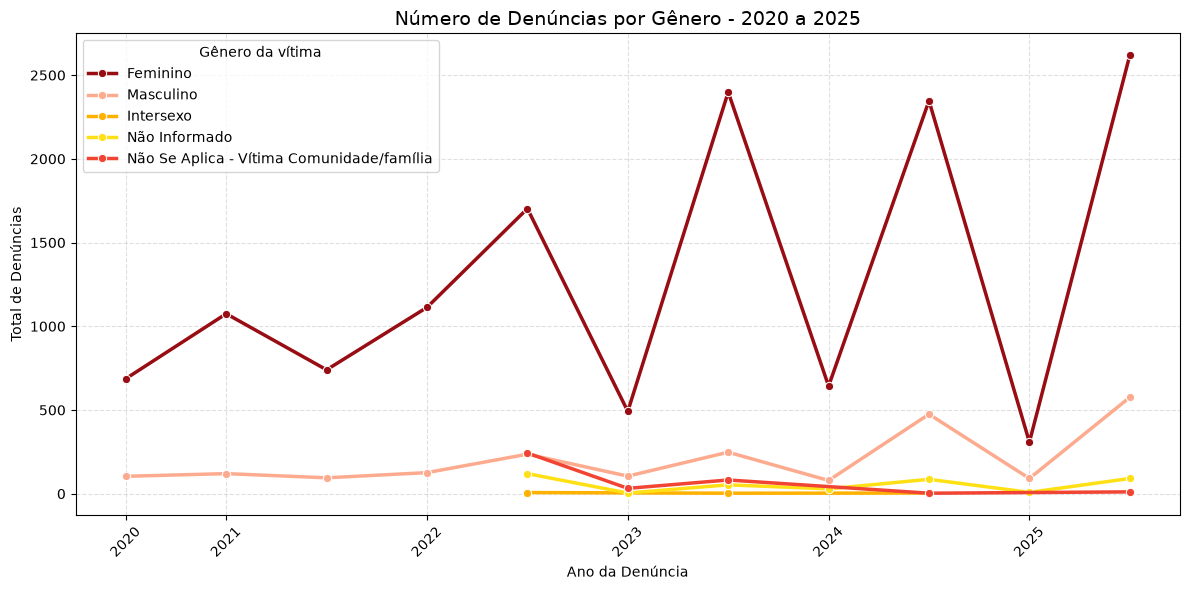

In [227]:
# numero de denuncias por anos
cmap = plt.cm.Reds
colors = cmap(np.linspace(0.3, 0.9, 3))
colors3 = colors[::-1]
cmap2 = plt.cm.Wistia
colors2 = cmap2(np.linspace(0.3, 0.9,3))
colors_t = [*colors3, *colors2]

generos = df_traf_mlg['genero_v'].unique()
palette_genero2 = dict(zip(generos, colors_t[:len(generos)]))

palette_genero = {
    "Feminino": "#D81B60",   # rosa forte (derivado do #ffc5d3)
    "Masculino": "#2E86C1",  # azul forte (derivado do #A7C7E7)
    "LGBTQIA+": "#6A3D9A",  # roxo para diferenciar
    "Não Informado": "#2E8B57",  # verde escuro
    "Não Se Aplica - Vítima Comunidade/família": "#E67E22"  # laranja (derivado do #FAC898)
}

fig, ax = plt.subplots(figsize=(12, 6))

df = df_traf_mlg[['genero_v','hash','ano_semestre']].groupby(['ano_semestre','genero_v'],as_index=False).count()

sns.lineplot(
    data=df,
    x='ano_semestre',
    y='hash',
    hue='genero_v',
    marker='o',
    linewidth=2.5,
    palette=palette_genero2
)

anos = df.groupby('ano_semestre',as_index=False).count()['ano_semestre'].str.split('_').str[0]
#labels = labels.unique()
tick_pos = [i for i in range(len(anos)) if i == 0 or anos[i] != anos[i-1]]
tick_labels = anos[tick_pos]

ax.set_xticks(tick_pos)
ax.set_xticklabels(tick_labels, rotation=45)


ax.set_title('Número de Denúncias por Gênero - 2020 a 2025', fontsize=14)
ax.set_xlabel('Ano da Denúncia')
ax.set_ylabel('Total de Denúncias')

ax.tick_params(axis='x', labelrotation=45)

ax.grid(True, linestyle='--', alpha=0.4)

plt.legend(title='Gênero da vítima')
plt.tight_layout()
#plt.ylim((0,1000))
#plt.savefig('charts_artigo\denuncias_tempo_por_genero.png')
plt.savefig(
    "denuncias_genero.png",
    dpi=300,
    transparent=True,
    bbox_inches="tight"
)
plt.show()

In [233]:
# df = seu DataFrame pandas
df = df_traf_mlg

df_v = df[['idade_v']].dropna().copy()
df_v['grupo'] = 'Vítimas'
df_v = df_v.rename(columns={'idade_v': 'idade'})

df_s = df[['idade_s']].dropna().copy()
df_s['grupo'] = 'Suspeitos'
df_s = df_s.rename(columns={'idade_s': 'idade'})

df_plot = pd.concat([df_v, df_s], ignore_index=True)
df_plot['idade'] = df_plot['idade'].apply(lambda x: str(x).replace(",","."))
df_plot['idade'] = df_plot['idade'].astype(float)

sns.set_theme(style="whitegrid")

cor_vitimas = "#FFBE00"
cor_suspeitos = "#BC141A"

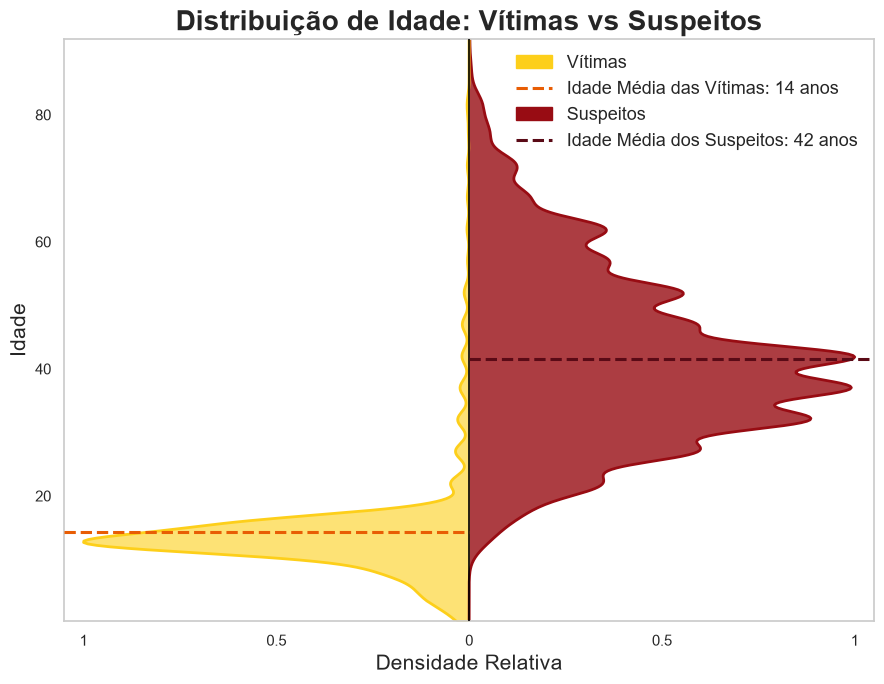

In [236]:
# df = seu DataFrame pandas
df = df_traf_mlg

df_v = df[['idade_v']].dropna().copy()
df_v['grupo'] = 'Vítimas'
df_v = df_v.rename(columns={'idade_v': 'idade'})

df_s = df[['idade_s']].dropna().copy()
df_s['grupo'] = 'Suspeitos'
df_s = df_s.rename(columns={'idade_s': 'idade'})

df_plot = pd.concat([df_v, df_s], ignore_index=True)
df_plot['idade'] = df_plot['idade'].apply(lambda x: str(x).replace(",","."))
df_plot['idade'] = df_plot['idade'].astype(float)

sns.set_theme(style="whitegrid")

cor_vitimas = "#FFBE00"
cor_suspeitos = "#BC141A"

# Dados (remove NA)
#v = df_plot.loc[df_plot["grupo"] == "Vítimas", "idade"].dropna().to_numpy()
#s = df_plot.loc[df_plot["grupo"] == "Suspeitos", "idade"].dropna().to_numpy()

v = df_plot.loc[df_plot["grupo"] == "Vítimas", "idade"].to_numpy()
s = df_plot.loc[df_plot["grupo"] == "Suspeitos", "idade"].to_numpy()

# AUMENTEI o tamanho aqui
fig, ax = plt.subplots(figsize=(9, 7))

cor_vitimas = "#FDCF1A" #colors_t[-1] #"#FFBE00"
cor_suspeitos = colors_t[0] #"#BC141A"

# KDE: domínio em idade
if v.size and s.size:
    x_min = min(v.min(), s.min())
    x_max = max(v.max(), s.max())
elif v.size:
    x_min, x_max = v.min(), v.max()
else:
    x_min, x_max = s.min(), s.max()

xs = np.linspace(x_min, x_max, 400)

def kde_scaled(data, xs):
    if data.size < 2:
        return np.zeros_like(xs)
    kde = gaussian_kde(data)
    dens = kde(xs)
    m = dens.max()
    return dens / m if m > 0 else dens

dens_v = kde_scaled(v, xs)
dens_s = kde_scaled(s, xs)

# Violino espelhado (metades separadas por x=0)
#ax.fill_betweenx(xs, 0,  dens_v, color=cor_vitimas, alpha=0.5, linewidth=0)
ax.fill_betweenx(xs, 0,  dens_s, color=cor_suspeitos, alpha=0.8, linewidth=0)
ax.plot(dens_s, xs, color=cor_suspeitos, linewidth=2.0)

#ax.fill_betweenx(xs, 0, -dens_s, color=cor_suspeitos, alpha=0.5, linewidth=0)
ax.fill_betweenx(xs, 0, -dens_v, color=cor_vitimas, alpha=0.6, linewidth=0)
ax.plot(-dens_v, xs, color=cor_vitimas, linewidth=2.0)

# Linha divisória
ax.axvline(0, color="black", linewidth=1.2, zorder=5)

# Eixos/título
#ax.set_xlabel("Densidade Relativa")
#ax.set_ylabel("Idade")

ax.set_xlabel("Densidade Relativa", fontsize=15)
ax.set_ylabel("Idade", fontsize=15)

ax.set_title("Distribuição de Idade: Vítimas vs Suspeitos",fontsize=20, fontweight="bold")
ax.grid(False)

ax.set_xlim(-1.05, 1.05)
ax.set_ylim(x_min, x_max)

# Médias (linhas horizontais)
mean_v = np.mean(v) if v.size else np.nan
mean_s = np.mean(s) if s.size else np.nan
xmin_plot, xmax_plot = ax.get_xlim()

line_v = ax.hlines(
    y=mean_s, xmin=0, xmax=xmax_plot,
    color='#5A0A16', linewidth=2.2, linestyle="--",
    zorder=10, label=f"Idade Média dos Suspeitos: {mean_s:.0f} anos"
)
line_s = ax.hlines(
    y=mean_v, xmin=xmin_plot, xmax=0,
    color='#E85D04', linewidth=2.2, linestyle="--",
    zorder=10, label=f"Idade Média das Vítimas: {mean_v:.0f} anos"
)

# Legenda
legend_items = [
    Patch(facecolor=cor_vitimas, edgecolor=cor_vitimas, alpha=1, label="Vítimas"),
    line_s,
    Patch(facecolor=cor_suspeitos, edgecolor=cor_suspeitos, alpha=1, label="Suspeitos"),
    line_v
]
ax.legend(handles=legend_items, loc="best", frameon=False, fontsize=13)

ticks = [-1, -0.5, 0, 0.5, 1]

ax.set_xticks(ticks)
ax.set_xticklabels([str(abs(t)) for t in ticks])

plt.tight_layout()
#plt.savefig("idade_vitima_suspeito2.png",dpi=300)
plt.savefig(
    "idade_vitima_suspeito.png",
    dpi=300,
    transparent=True,
    bbox_inches="tight"
)
plt.show()

In [245]:
df_traf_mlg['genero_s'].unique()

<StringArray>
[                                'Masculino',
                                  'Feminino',
                             'Não Informado',
                                         nan,
 'Não Se Aplica - Vítima Comunidade/família',
                                 'Intersexo']
Length: 6, dtype: str

In [248]:
df_traf_mlg.columns

Index(['hash', 'Data_de_cadastro', 'UF', 'Município', 'violacao',
       'Gênero_da_vítima', 'Faixa_etária_da_vítima', 'Raça_Cor_da_vítima',
       'Relação_vítima_suspeito', 'Gênero_do_suspeito',
       'Faixa_etária_do_suspeito', 'Cenário_da_violação', 'estado',
       'municipio', 'chave', 'data', 'ano_mes', 'ano', 'semestre',
       'ano_semestre', 'genero_v', 'genero_s', 'idade_v', 'idade_s', 'cor_v',
       'cenario', 'relacao_v_s', 'tipo_violacao', 'pandemia'],
      dtype='str')

In [254]:
# Cores
cor_fem = "#FFBE00"
cor_masc = "#BC141A"

generos = ["Feminino", "Masculino","Não se Aplica",'Não Informado','Não Se Aplica - Vítima Comunidade/família','Intersexo']
cor_map = {
    generos[0]: cor_fem,
    generos[1]: cor_masc,
    generos[2]: "#50C878",
    generos[3]: "#50C878",
    generos[4]: "#50C878",
    generos[5]: "#50C878"
}

# Filtrar NAs
df = df_traf_mlg.copy()
df = df.dropna(subset=["genero_s", "idade_s"])

# Ordem (garante consistência dos eixos)
#df["Gênero_do_suspeito"] = df["Gênero_do_suspeito"].map(dict_genero)
df = df[df['genero_s'].isin(["Feminino", "Masculino"])]
df["Gênero_do_suspeito"] = pd.Categorical(df["genero_s"], categories=generos, ordered=True)

# -------- 1) Proporção de suspeitos por gênero --------
prop = (
    df.groupby("Gênero_do_suspeito")
      .size()
      .reset_index(name="n")
)
prop["prop"] = prop["n"] / prop["n"].sum()
prop

,Gênero_do_suspeito,n,prop
0,Feminino,6405,0.44684
1,Masculino,7929,0.55316


C:\Users\rosan\AppData\Local\Temp\ipykernel_12788\18555890.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\rosan\AppData\Local\Temp\ipykernel_12788\18555890.py:5: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  sns.violinplot(


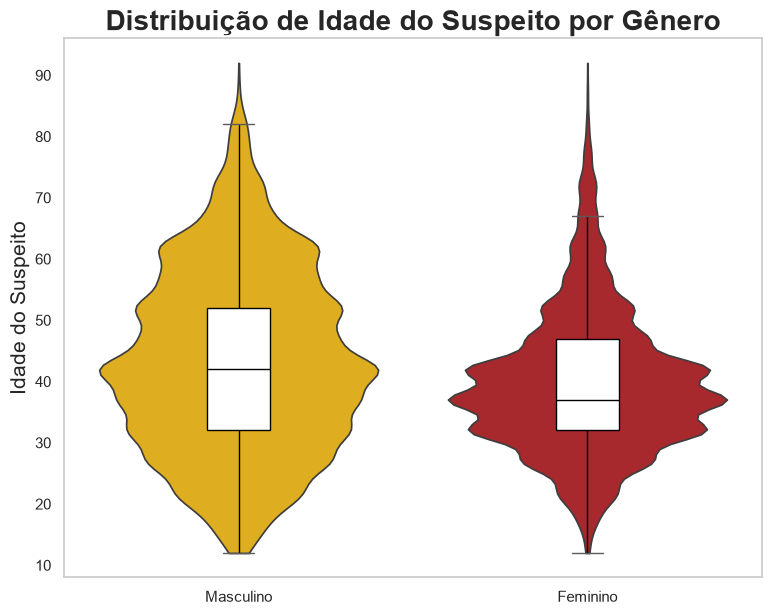

In [264]:
# -------- 1) Proporção de suspeitos por gênero --------
fig, ax = plt.subplots(figsize=(9, 7))

# -------- 2) Distribuição de idades por gênero (violino) --------
sns.violinplot(
    data=df[df['genero_s'].isin(["Feminino", "Masculino"])],
    x="genero_s",
    y="idade_s",
    palette=[cor_map[g] for g in generos],
    inner=None,
    cut=0
)

sns.boxplot(
    data=df[df['genero_s'].isin(["Feminino", "Masculino"])],
    x="genero_s",
    y="idade_s",
    width=0.18,
    showfliers=False,
    boxprops={"facecolor": "white", "edgecolor": "black", "linewidth": 1},
    whiskerprops={"color": "black", "linewidth": 1},
    medianprops={"color": "black", "linewidth": 1}
)

ax.set_xlabel("", fontsize=15)
ax.set_ylabel("Idade do Suspeito", fontsize=15)

ax.set_title("Distribuição de Idade do Suspeito por Gênero",fontsize=20, fontweight="bold")
ax.grid(False)

plt.legend_.remove() if ax.get_legend() else None


plt.savefig(
    "genero_idade_suspeito.png",
    dpi=300,
    transparent=True,
    bbox_inches="tight"
)
plt.show()

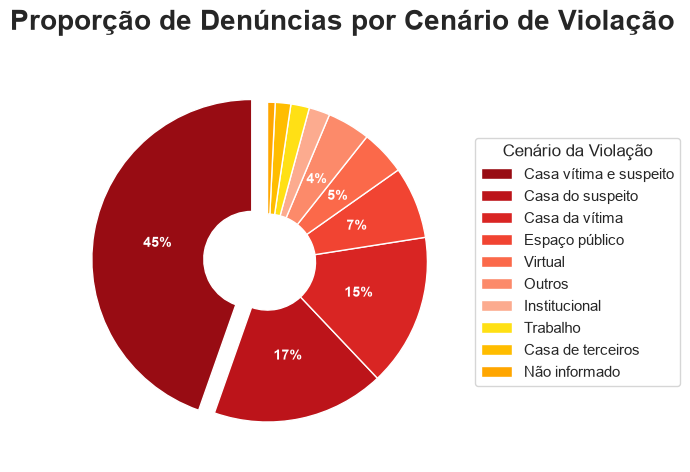

In [239]:
fig, ax = plt.subplots()

df = df_traf_mlg[['hash','cenario']].groupby('cenario', as_index=False).count().sort_values('hash',ascending=False)
labels = df['cenario'].tolist()
cmap = plt.cm.Reds
colors = cmap(np.linspace(0.3, 0.9, 7))
colors3 = colors[::-1]
cmap2 = plt.cm.Wistia
colors2 = cmap2(np.linspace(0.3, 0.9, 4))
colors_t = [*colors3, *colors2]
explode = [0.1 if i == 0 else 0 for i in range(len(labels))]

wedges, texts, autotexts = ax.pie(
    df['hash'],
    colors=colors_t,
    startangle=90,
    autopct='%.0f%%',
    wedgeprops=dict(width=0.7),
    explode=explode
)

# estilizando as porcentagens
i = 1
for autotext in autotexts:
    if autotext.get_text() != '':
        autotext.set_color("white")
        autotext.set_fontsize(10)
        autotext.set_weight("bold")
        if float(autotext.get_text().replace("%","")) < 4:
            autotext.set_text('') 

ax.legend(wedges, df['cenario'], title="Cenário da Violação", loc="center left",
          bbox_to_anchor=(1, 0, 0.5, 1))
plt.suptitle("Proporção de Denúncias por Cenário de Violação",fontsize=20,fontweight="bold")

plt.tight_layout()
#data_path = fr'{project_path}\data\charts'
plt.savefig(r'viol_cena2.png', dpi=300,transparent=True,
    bbox_inches="tight")

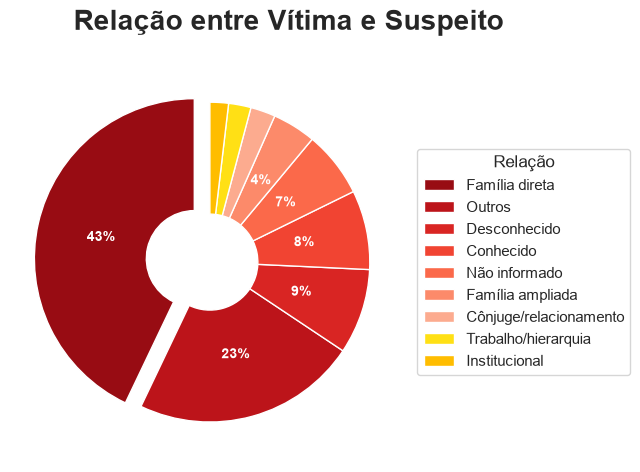

In [244]:
fig, ax = plt.subplots()

df = df_traf_mlg[['hash','relacao_v_s']].groupby('relacao_v_s', as_index=False).count().sort_values('hash',ascending=False)
labels = df['relacao_v_s'].tolist()
cmap = plt.cm.Reds
colors = cmap(np.linspace(0.3, 0.9, 7))
colors3 = colors[::-1]
cmap2 = plt.cm.Wistia
colors2 = cmap2(np.linspace(0.3, 0.9, 4))
colors_t = [*colors3, *colors2]
explode = [0.1 if i == 0 else 0 for i in range(len(labels))]

wedges, texts, autotexts = ax.pie(
    df['hash'],
    colors=colors_t,
    startangle=90,
    autopct='%.0f%%',
    wedgeprops=dict(width=0.7),
    explode=explode
)

# estilizando as porcentagens
i = 1
for autotext in autotexts:
    if autotext.get_text() != '':
        autotext.set_color("white")
        autotext.set_fontsize(10)
        autotext.set_weight("bold")
        if float(autotext.get_text().replace("%","")) < 4:
            autotext.set_text('') 

ax.legend(wedges, df['relacao_v_s'], title="Relação", loc="center left",
          bbox_to_anchor=(1, 0, 0.5, 1))
plt.suptitle(f'Relação entre Vítima e Suspeito',fontsize=20,fontweight="bold")
plt.tight_layout()
#data_path = fr'{project_path}\data\charts'
plt.savefig(r'vit_e_susp_relacao2.png',dpi=300,transparent=True,
    bbox_inches="tight")

In [275]:
dict_cor = {
    "PARDA":"Parda",
    "BRANCA":"Branca",
    "NÃO INFORMADO":"Não Informado",
    "PRETA":"Preta",
    "INDÍGENA":"Indígena",
    "AMARELA":"Amarela"
}

dict_cor_cor = {
    "Parda": "#cc985a",
    "Branca": "#f4d0a3",
    "Não Informado":"#50C878",
    "Preta": "#623A18",
    "Indígena": "#dba827",
    "Amarela": "#FBEC5D"
}

In [331]:
df2 = df_traf_mlg[['cor_v','hash']].groupby('cor_v', as_index=False).count()
df2['cor_v'] = pd.Categorical(
    df2['cor_v'],
    ordered=True
)
df2 = df2.sort_values('hash',ascending=False)

In [332]:
df2['cor'] = df2['cor_v'].map(dict_cor_cor)

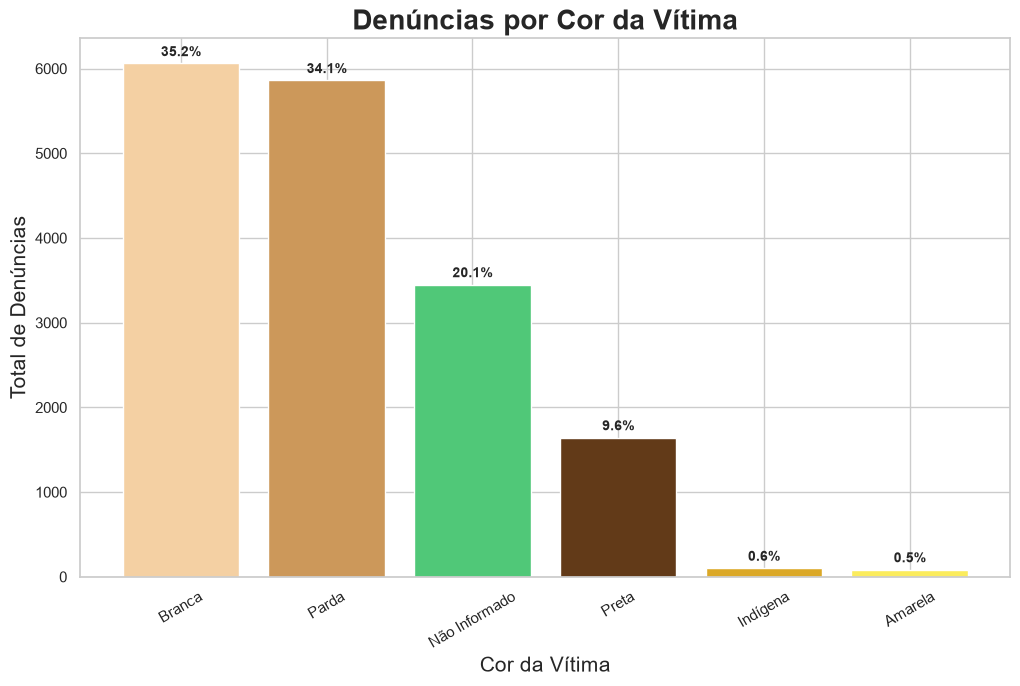

In [340]:
dict_cor = {
    "PARDA":"Parda",
    "BRANCA":"Branca",
    "NÃO INFORMADO":"Não Informado",
    "PRETA":"Preta",
    "INDÍGENA":"Indígena",
    "AMARELA":"Amarela"
}

dict_cor_cor = {
    "Parda": "#cc985a",
    "Branca": "#f4d0a3",
    "Não Informado":"#50C878",
    "Preta": "#623A18",
    "Indígena": "#dba827",
    "Amarela": "#FBEC5D"
}
df2 = df_traf_mlg[['cor_v','hash']].groupby('cor_v', as_index=False).count()
df2['cor_v'] = pd.Categorical(
    df2['cor_v'],
    ordered=True
)
df2 = df2.sort_values('hash',ascending=False)
df2['cor'] = df2['cor_v'].map(dict_cor_cor)

fig, ax = plt.subplots(figsize=(12,7),ncols=1,nrows=1)

ax.bar(
    df2['cor_v'],
    df2['hash'],
    color=df2['cor']
)
total = df2['hash'].sum()

for i, v in enumerate(df2['hash']):
    pct = 100 * v / total

    ax.text(
        i,
        v + total*0.005,
        f'{pct:.1f}%',
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

ax.set_ylabel("Total de Denúncias",fontsize=15)
#ax[0].set_xticks([])
ax.set_xlabel("Cor da Vítima",fontsize=15)

plt.title('Denúncias por Cor da Vítima',fontsize=20,fontweight="bold")

ax.tick_params(axis='x', rotation=30)

plt.savefig(r'grafico_vio_e_cor.png',dpi=300,transparent=True,
    bbox_inches="tight")
plt.show()

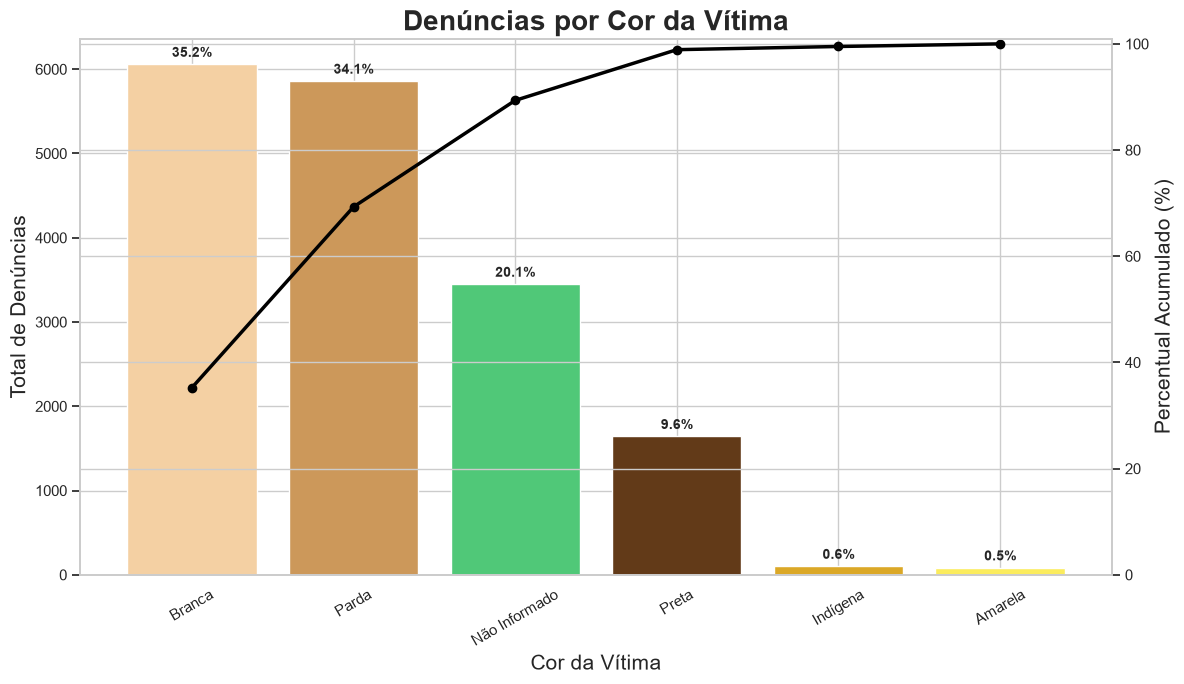

In [337]:
# Ordena do maior para o menor número de denúncias
df_pareto = df2.sort_values('hash', ascending=False).reset_index(drop=True)

# Total de denúncias
total = df_pareto['hash'].sum()

# Percentual individual e acumulado
df_pareto['pct'] = 100 * df_pareto['hash'] / total
df_pareto['pct_acum'] = df_pareto['pct'].cumsum()

# Figura e eixos
fig, ax = plt.subplots(figsize=(12, 7))

# Barras
bars = ax.bar(
    df_pareto['cor_v'],
    df_pareto['hash'],
    color=df_pareto['cor']
)

# Percentual individual acima das barras
for i, v in enumerate(df_pareto['hash']):
    pct = df_pareto.loc[i, 'pct']

    ax.text(
        i,
        v + total * 0.005,
        f'{pct:.1f}%',
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

# Eixo principal
ax.set_ylabel('Total de Denúncias',fontsize=15)
ax.set_xlabel('Cor da Vítima',fontsize=15)
ax.tick_params(axis='x', rotation=30)

# Segundo eixo: percentual acumulado
ax2 = ax.twinx()

ax2.plot(
    range(len(df_pareto)),
    df_pareto['pct_acum'],
    color='black',
    marker='o',
    linewidth=2.5
)

ax2.set_ylabel('Percentual Acumulado (%)',fontsize=15)
ax2.set_ylim(0, 101)

plt.title('Denúncias por Cor da Vítima',fontsize=20,fontweight="bold")

plt.tight_layout()
plt.show()

In [174]:
# mapa

# API DE MALHA GEOGRAFICA - IBGE

import requests
import json

def buscar_dados_geo(uf):    
    #Define a URL de busca com produto e limite
    url_busca = f"https://servicodados.ibge.gov.br/api/v4/malhas/estados/{uf}/metadados"
    
    #Envia requisição GET
    request = requests.get(url_busca)
    
    #Define dicionário para tratar dados
    malha = json.loads(request.content)
    
    url_busca2 = f"https://servicodados.ibge.gov.br/api/v4/malhas/estados/{uf}?formato=application/vnd.geo+json"

    #Envia requisição GET
    request = requests.get(url_busca2)

    #Define dicionário para tratar dados
    malha2 = json.loads(request.content)
    
    return malha, malha2

In [175]:
dict_uf = {
    'AC': ('Acre', 12, -9.97499, -67.8243),
    'AL': ('Alagoas', 27, -9.66599, -35.7350),
    'AP': ('Amapá', 16, 0.03493, -51.0694),
    'AM': ('Amazonas', 13, -3.11903, -60.0217),
    'BA': ('Bahia', 29, -12.9718, -38.5011),
    'CE': ('Ceará', 23, -3.71722, -38.5433),
    'DF': ('Distrito Federal', 53, -15.7939, -47.8828),
    'ES': ('Espírito Santo', 32, -20.3155, -40.3128),
    'GO': ('Goiás', 52, -16.6864, -49.2643),
    'MA': ('Maranhão', 21, -2.53073, -44.3068),
    'MT': ('Mato Grosso', 51, -15.6014, -56.0979),
    'MS': ('Mato Grosso do Sul', 50, -20.4697, -54.6201),
    'MG': ('Minas Gerais', 31, -19.9167, -43.9345),
    'PA': ('Pará', 15, -1.45583, -48.4902),
    'PB': ('Paraíba', 25, -7.11532, -34.8610),
    'PR': ('Paraná', 41, -25.4284, -49.2733),
    'PE': ('Pernambuco', 26, -8.04756, -34.8770),
    'PI': ('Piauí', 22, -5.09194, -42.8034),
    'RN': ('Rio Grande do Norte', 24, -5.79448, -35.2110),
    'RS': ('Rio Grande do Sul', 43, -30.0346, -51.2177),
    'RJ': ('Rio de Janeiro', 33, -22.9068, -43.1729),
    'RO': ('Rondônia', 11, -8.76077, -63.8999),
    'RR': ('Roraima', 14, 2.82384, -60.6753),
    'SC': ('Santa Catarina', 42, -27.5949, -48.5482),
    'SP': ('São Paulo', 35, -23.5505, -46.6333),
    'SE': ('Sergipe', 28, -10.9472, -37.0731),
    'TO': ('Tocantins', 17, -10.1840, -48.3336)
}

In [176]:
lista = []
malha = []
for uf, est in dict_uf.items():
    dados, malha_geo = buscar_dados_geo(est[1])
    lista.append((est[1],dados[0]['id'],dados[0]['centroide']['latitude'],dados[0]['centroide']['longitude'], est[0], uf))
    malha.append(malha_geo.get('features')[0])

In [177]:
geo_json_dados = {
    "type": "FeatureCollection",
    "features": malha
}

In [178]:
with open(r"C:\Users\rosan\Projeto\Dashboard-HT\src\utils\brasil_estados.geojson", "w", encoding="utf-8") as f:
    json.dump(geo_json_dados, f, ensure_ascii=False, indent=2)

In [179]:
df_lat_long = pd.DataFrame(lista, columns=['estado','id','lat','long','nome_estado','UF'])
df_lat_long['id'] = df_lat_long['id'].astype(int)
#df_lat_long['estado'] = df_lat_long['estado'].apply(lambada x: dict_uf[x][0])
df_lat_long.head(5)

,estado,id,lat,long,nome_estado,UF
0,12,12,-9.2130,-70.4721,Acre,AC
1,27,27,-9.5137,-36.6248,Alagoas,AL
2,16,16,1.4443,-51.9638,Amapá,AP
3,13,13,-4.1561,-64.6524,Amazonas,AM
4,29,29,-12.4753,-41.7212,Bahia,BA


In [180]:
df_lat_long.to_csv(r"C:\Users\rosan\Projeto\Dashboard-HT\src\utils\df_uf.csv",sep=";",index=False)

In [360]:
# numero de denuncias por estado

df_traf_mlg_2 = df_traf_mlg

df_traf_mlg_2 = df_traf_mlg_2[['estado','ano','hash']].groupby(['estado','ano'],as_index=False).count()
df_teste_origem = df_lat_long.merge(df_traf_mlg_2, left_on = 'UF', right_on='estado', how='inner')
df_teste_origem['proporcao'] = df_teste_origem['hash']*100/sum(df_teste_origem['hash'])
df_teste_origem.head()

,estado_x,id,lat,long,nome_estado,UF,estado_y,ano,hash,proporcao
0,12,12,-9.213,-70.4721,Acre,AC,AC,2020,1,0.005153
1,12,12,-9.213,-70.4721,Acre,AC,AC,2021,2,0.010306
2,12,12,-9.213,-70.4721,Acre,AC,AC,2022,7,0.036069
3,12,12,-9.213,-70.4721,Acre,AC,AC,2023,2,0.010306
4,12,12,-9.213,-70.4721,Acre,AC,AC,2024,41,0.211264


In [351]:
mapa = folium.Map(
            location = [df_teste_origem['lat'].mean(),df_teste_origem['long'].mean()],
            zoom_start = 4
)

folium.Choropleth(
    geo_data=geo_json_dados,
    data=df_teste_origem,
    columns=['id',"hash"],
    key_on="feature.properties.codarea",
    fill_color='RdBu',
    fill_opacity=1,
    line_opacity=0.2
).add_to(mapa)

for indice, linha in df_teste_origem.iterrows():
    soma_uf = sum(df_teste_origem[df_teste_origem['UF'] == linha.estado_y]['hash'])
    nome = f'Número total de vítimas do estado {linha.nome_estado}: {soma_uf}'
    localizacao = [linha.lat,linha.long]
    #vis1 = json.loads(bar1.to_json())
    popup = folium.Popup(max_width=500)#.add_child(folium.VegaLite(vis1,height=150, width=1000))
    pin = folium.Marker(location = localizacao, popup=popup, tooltip = f'Número de vítimas de {linha.nome_estado}: {linha.hash}')
    pin.add_to(mapa)

#mapa.save('mapa_nota_media_enem.html')
mapa

In [357]:
mapa = folium.Map(
            location = [df_teste_origem['lat'].mean(),df_teste_origem['long'].mean()],
            zoom_start = 4
)

folium.Choropleth(
    geo_data=geo_json_dados,
    data=df_teste_origem,
    columns=['id',"hash"],
    key_on="feature.properties.codarea",
    fill_color='RdBu',
    fill_opacity=1,
    line_opacity=0.2
).add_to(mapa)

for indice, linha in df_teste_origem.iterrows():

    folium.Marker(
        location=[linha.lat, linha.long],
        icon=folium.DivIcon(
            html=f"""
            <div style="
                font-size:12px;
                font-weight:bold;
                color:black;
                text-align:center;
            ">
                {linha.estado_y}
            </div>
            """
        )
    ).add_to(mapa)
    
    
legenda = """
<div style="
position: fixed; 
bottom: 20px; right: 50px; 
width: 250px; 
background-color: white;
border:2px solid grey;
z-index:9999;
font-size:14px;
padding:10px;
">
<b>Total de Vítimas por Estado de Origem</b><br>
"""

for indice, linha in df_teste_origem.sort_values('hash',ascending=False).iterrows():
    legenda += f"{linha.estado_y} - {linha.nome_estado}: {linha.hash} ({round(linha.proporcao,2)}%)<br>"

legenda += "</div>"
mapa.get_root().html.add_child(folium.Element(legenda))
mapa.save('mapa_vitimas_por_estado.html')
mapa

In [373]:
df_teste_origem

,estado_x,id,lat,long,nome_estado,UF,estado_y,ano,hash,proporcao
0,12,12,-9.2130,-70.4721,Acre,AC,AC,2020,1,0.005153
1,12,12,-9.2130,-70.4721,Acre,AC,AC,2021,2,0.010306
2,12,12,-9.2130,-70.4721,Acre,AC,AC,2022,7,0.036069
3,12,12,-9.2130,-70.4721,Acre,AC,AC,2023,2,0.010306
4,12,12,-9.2130,-70.4721,Acre,AC,AC,2024,41,0.211264
...,...,...,...,...,...,...,...,...,...,...
157,17,17,-10.1481,-48.3313,Tocantins,TO,TO,2021,16,0.082444
158,17,17,-10.1481,-48.3313,Tocantins,TO,TO,2022,14,0.072139
159,17,17,-10.1481,-48.3313,Tocantins,TO,TO,2023,25,0.128819
160,17,17,-10.1481,-48.3313,Tocantins,TO,TO,2024,30,0.154583


In [378]:
mapa = folium.Map(
            location = [df_teste_origem['lat'].mean(),df_teste_origem['long'].mean()],
            zoom_start = 4
)

folium.Choropleth(
    geo_data=geo_json_dados,
    data=df_teste_origem,
    columns=['id',"hash"],
    key_on="feature.properties.codarea",
    fill_color='RdBu',
    fill_opacity=1,
    line_opacity=0.2
).add_to(mapa)

for indice, linha in df_teste_origem.iterrows():

    folium.Marker(
        location=[linha.lat, linha.long],
        icon=folium.DivIcon(
            html=f"""
            <div style="
                font-size:12px;
                font-weight:bold;
                color:black;
                text-align:center;
            ">
                {linha.estado_y}
            </div>
            """
        )
    ).add_to(mapa)
    vis1 = json.loads(grafico_temp_uf(linha.estado_y).to_json())
    popup = folium.Popup(max_width=500).add_child(folium.VegaLite(vis1,height=300, width=1000))
    pin = folium.Marker(location = [linha.lat, linha.long], popup=popup, tooltip = f"Número de Vítimas em {linha.nome_estado}")
    pin.add_to(mapa)
    
legenda = """
<div style="
position: fixed; 
bottom: 30px; right: 50px; 
width: 250px; 
background-color: white;
border:2px solid grey;
z-index:9999;
font-size:14px;
padding:10px;
">
<b>Total de Vítimas por Estado</b><br>
"""

for indice, linha in df_teste_origem.sort_values('hash',ascending=False).iterrows():
    legenda += f"{linha.estado_y} - {linha.nome_estado}: {linha.hash} ({round(linha.proporcao,2)}%)<br>"

legenda += "</div>"
mapa.get_root().html.add_child(folium.Element(legenda))
#mapa.save('mapa_vitimas_por_estado_legenda.html')
mapa

In [359]:
df

,hash,Data_de_cadastro,UF,Município,violacao,Gênero_da_vítima,Faixa_etária_da_vítima,Raça_Cor_da_vítima,Relação_vítima_suspeito,Gênero_do_suspeito,...,ano_semestre,genero_v,genero_s,idade_v,idade_s,cor_v,cenario,relacao_v_s,tipo_violacao,pandemia
1,CBE664208C98A9531864D7E72A0654EF743BDF573871A3...,19/10/2022 13:22,PA,150140 | BELEM,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL,FEMININO,04 ANOS,INDÍGENA,OUTROS,MASCULINO,...,2022_2,Feminino,Masculino,4.0,37.0,Indígena,Espaço público,Outros,EXPLORAÇÃO SEXUAL,0
2,C6232BC440F76CA15780BB8A6656FF5D39EC7C399F4129...,30/10/2022 11:20,PA,150010 | ABAETETUBA,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL,FEMININO,11 ANOS,PARDA,PADRASTO/MADRASTA,MASCULINO,...,2022_2,Feminino,Masculino,11.0,37.0,Parda,Institucional,NaN,EXPLORAÇÃO SEXUAL,0
4,41BA8F28E1FA1800384C52E4EABF1F46CAB72685461B48...,05/12/2022 17:45,BA,292990 | SEABRA,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL,FEMININO,08 ANOS,PARDA,DESCONHECIDO(A),MASCULINO,...,2022_2,Feminino,Masculino,8.0,52.0,Parda,Casa vítima e suspeito,Desconhecido,EXPLORAÇÃO SEXUAL,0
6,73AF6BC51A27CBBF19B0FB5C7468018B7672749FC888AF...,11/12/2022 13:44,RJ,330150 | CORDEIRO,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL,FEMININO,15 ANOS,BRANCA,NÃO SABE INFORMAR,FEMININO,...,2022_2,Feminino,Feminino,15.0,22.0,Branca,Casa do suspeito,Não informado,EXPLORAÇÃO SEXUAL,0
7,87AAB27822D56B8BD2F2D15F47635F7AF161CE1EE162E0...,18/12/2022 18:26,GO,521190 | JATAI,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL,NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA,CRIANÇA/ADOLESCENTE IDADE NÃO INFORMADA,NÃO INFORMADO,NÃO SE APLICA,FEMININO,...,2022_2,Não Se Aplica - Vítima Comunidade/família,Feminino,12.0,42.0,Não Informado,Espaço público,Não informado,EXPLORAÇÃO SEXUAL,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21220,D512BA8B7B8814E66F2E6453CB37FF467AD5246DB412F8...,2025-12-31 08:10:24.967,MG,3103009 | ANTONIO DIAS,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL,FEMININO,15 ANOS,BRANCA,MÃE,FEMININO,...,2025_2,Feminino,Feminino,15.0,37.0,Branca,Outros,Família direta,EXPLORAÇÃO SEXUAL,0
21223,CB4FEA141B079943ADB160CCE4ACB0F1A4CB467F43E6C3...,2025-12-31 11:00:16.400,SP,3543402 | RIBEIRAO PRETO,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL,FEMININO,15 ANOS,PARDA,MÃE,FEMININO,...,2025_2,Feminino,Feminino,15.0,42.0,Parda,Casa vítima e suspeito,Família direta,EXPLORAÇÃO SEXUAL,0
21224,905642D93360CB4096BFA7F714ADFECC575E3CB21D8253...,2025-12-31 11:00:16.400,SP,3543402 | RIBEIRAO PRETO,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL,FEMININO,15 ANOS,PARDA,MÃE,MASCULINO,...,2025_2,Feminino,Masculino,15.0,52.0,Parda,Casa vítima e suspeito,Família direta,EXPLORAÇÃO SEXUAL,0
21226,F2BDA31B1706F0EB09C55FD0608962111F8F38B06F9402...,2025-12-31 20:13:17.977,RS,4314902 | PORTO ALEGRE,LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL,MASCULINO,08 ANOS,BRANCA,PAI,MASCULINO,...,2025_2,Masculino,Masculino,8.0,57.0,Branca,Casa do suspeito,Família direta,EXPLORAÇÃO SEXUAL,0


In [361]:
df_teste_origem

,estado_x,id,lat,long,nome_estado,UF,estado_y,ano,hash,proporcao
0,12,12,-9.2130,-70.4721,Acre,AC,AC,2020,1,0.005153
1,12,12,-9.2130,-70.4721,Acre,AC,AC,2021,2,0.010306
2,12,12,-9.2130,-70.4721,Acre,AC,AC,2022,7,0.036069
3,12,12,-9.2130,-70.4721,Acre,AC,AC,2023,2,0.010306
4,12,12,-9.2130,-70.4721,Acre,AC,AC,2024,41,0.211264
...,...,...,...,...,...,...,...,...,...,...
157,17,17,-10.1481,-48.3313,Tocantins,TO,TO,2021,16,0.082444
158,17,17,-10.1481,-48.3313,Tocantins,TO,TO,2022,14,0.072139
159,17,17,-10.1481,-48.3313,Tocantins,TO,TO,2023,25,0.128819
160,17,17,-10.1481,-48.3313,Tocantins,TO,TO,2024,30,0.154583


In [367]:
df

,nome_estado,ano,hash
0,São Paulo,2020,207
1,São Paulo,2021,498
2,São Paulo,2022,683
3,São Paulo,2023,749
4,São Paulo,2024,919
5,São Paulo,2025,863


In [368]:
uf='SP'
df = df_teste_origem[df_teste_origem['UF']==uf][['nome_estado','hash','ano']].groupby(['nome_estado','ano'],as_index=False).sum()


chart1 = (
    alt.Chart(df)
    .mark_line(
        point=True
    )
    .encode(
        x=alt.X(
            'ano:O',
            title='Ano'
        ),
        y=alt.Y(
            'hash:Q',
            title='Total de Denúncias'
        ),
        tooltip=[
            alt.Tooltip('ano:O', title='Ano'),
            alt.Tooltip('hash:Q', title='Denúncias', format=',')
        ]
    )
    .properties(
        width=250,
        height=150,
        title=f'Tráfico Humano - {uf}'
    )
)

text = (
    alt.Chart(df)
    .mark_text(
        dy=-10,
        fontSize=10
    )
    .encode(
        x=alt.X('ano:O'),
        y=alt.Y('hash:Q'),
        text=alt.Text('hash:Q', format=',')
    )
)

chart = chart1 + text

chart

alt.LayerChart(...)

In [372]:
grafico_temp_uf('MG')

alt.LayerChart(...)

In [371]:
import altair as alt

uf = 'SP'

def grafico_temp_uf(uf):
    
    df = (
        df_teste_origem[
            df_teste_origem['UF'] == uf
        ][['nome_estado', 'hash', 'ano']]
        .groupby(['nome_estado', 'ano'], as_index=False)
        .sum()
        .sort_values('ano')
    )
    
    # Série temporal
    chart1 = (
        alt.Chart(df)
        .mark_line(
            point=True,
            color='#2563eb'
        )
        .encode(
            x=alt.X(
                'ano:O',
                title='Ano'
            ),
            y=alt.Y(
                'hash:Q',
                title='Total de Denúncias'
            ),
            tooltip=[
                alt.Tooltip('ano:O', title='Ano'),
                alt.Tooltip('hash:Q', title='Denúncias', format=',')
            ]
        )
    )
    
    # Linhas verticais
    linhas = (
        alt.Chart(
            alt.Data(values=[
                {'ano': 2020},
                {'ano': 2023}
            ])
        )
        .mark_rule(
            color='red',
            strokeDash=[5, 5],
            strokeWidth=2
        )
        .encode(
            x=alt.X(
                'ano:O',
                scale=alt.Scale(domain=sorted(df['ano'].unique()))
            )
        )
    )
    
    # Valores sobre os pontos
    text = (
        alt.Chart(df)
        .mark_text(
            dy=-10,
            fontSize=10
        )
        .encode(
            x='ano:O',
            y='hash:Q',
            text=alt.Text('hash:Q', format=',')
        )
    )
    
    chart = (
        chart1 + linhas + text
    ).properties(
        width=400,
        height=250,
        title=f'Tráfico Humano - {uf}'
    )
    
    return chart


In [ ]:
estado_y

In [ ]:
df_traf_mlg[['chave','estado','municipio','hash','Data_de_cadastro','data','ano','ano_semestre']]

In [149]:
df_traf_mlg2 = df_traf_mlg[['chave','estado','municipio','hash','Data_de_cadastro','data','ano','ano_semestre','pandemia']].groupby(['chave','estado','municipio','Data_de_cadastro','data','ano','ano_semestre','pandemia'],as_index=False).count().sort_values('hash',ascending=False)
df_traf_mlg2.head()

,chave,estado,municipio,Data_de_cadastro,data,ano,ano_semestre,pandemia,hash
4351,MG/UBERLANDIA,MG,UBERLANDIA,2025-07-20 18:47:24.913,2025-07-20,2025,2025_2,0,54
11921,SP/VERA CRUZ,SP,VERA CRUZ,2024-07-24 18:10:03.217,2024-07-24,2024,2024_2,0,36
2939,MA/CAXIAS,MA,CAXIAS,2025-07-28 12:02:59.267,2025-07-28,2025,2025_2,0,35
4262,MG/TUPACIGUARA,MG,TUPACIGUARA,2024-12-04 06:50:51.637,2024-12-04,2024,2024_2,0,27
9351,SE/ARACAJU,SE,ARACAJU,2025-04-21 13:15:30.813,2025-04-21,2025,2025_1,0,24


In [18]:
# dados 

df_ht = pd.read_csv(r"C:\Users\rosan\Projeto\Disque100\src\data\out\mlg\disque100_mlg_ajustado.csv",sep=";")
df_ht.head()

C:\Users\rosan\AppData\Local\Temp\ipykernel_11776\2736968925.py:3: DtypeWarning: Columns (21: violacao_ajust) have mixed types. Specify dtype option on import or set low_memory=False.
  df_ht = pd.read_csv(r"C:\Users\rosan\Projeto\Disque100\src\data\out\mlg\disque100_mlg_ajustado.csv",sep=";")


,Data_de_cadastro,Gênero_da_vítima,Raça_Cor_da_vítima,Faixa_etária_da_vítima,Gênero_do_suspeito,Faixa_etária_do_suspeito,Relação_vítima_suspeito,Cenário_da_violação,violacao,Município,...,Relação_vítima_suspeito_ajust,Cenário_da_violação_ajust,violacao_ajust,Município_ajust,UF_ajust,data,ano_mes,ano,semestre,ano_semestre
0,2011-01-05 21:01:57.000,Feminino,Branca,18 a 24 anos,Feminino,51 a 55 anos,Mãe,Casa,VIOLÊNCIA SEXUAL.EXPLORAÇÃO SEXUAL;TORTURA E O...,Não Informado,...,Família direta,Casa,NaN,Não Informado,Não Informado,2011-01-05,2011-01,2011,1,2011_1
1,2011-01-05 21:01:57.000,Feminino,Branca,18 a 24 anos,Feminino,Não Informado,Amigo (a),Casa,VIOLÊNCIA SEXUAL.EXPLORAÇÃO SEXUAL;VIOLÊNCIA P...,Não Informado,...,Conhecido,Casa,NaN,Não Informado,Não Informado,2011-01-05,2011-01,2011,1,2011_1
2,2011-01-08 08:45:33.000,Masculino,Branca,18 a 24 anos,Feminino,Não Informado,Mãe,Casa,VIOLÊNCIA SEXUAL.EXPLORAÇÃO SEXUAL;VIOLÊNCIA S...,Não Informado,...,Família direta,Casa,NaN,Não Informado,Não Informado,2011-01-08,2011-01,2011,1,2011_1
3,2011-01-08 10:55:15.000,Feminino,Branca,18 a 24 anos,Feminino,31 a 35 anos,Desconhecido(a),Casa,VIOLÊNCIA SEXUAL.EXPLORAÇÃO SEXUAL;VIOLÊNCIA F...,Não Informado,...,Desconhecido,Casa,NaN,Não Informado,Não Informado,2011-01-08,2011-01,2011,1,2011_1
4,2011-01-09 16:10:39.000,Não informado,Branca,Não Informado,Feminino,Não Informado,Mãe,Rua,VIOLÊNCIA SEXUAL.EXPLORAÇÃO SEXUAL;VIOLÊNCIA S...,Não Informado,...,Família direta,Espaço público,NaN,Não Informado,Não Informado,2011-01-09,2011-01,2011,1,2011_1


In [19]:
df_ht['data'].min()

'2011-01-05'

In [20]:
df_ht['data'].max()

'2026-06-30'

In [21]:
df_ht[~df_ht['Município'].isna()].shape

(117991, 29)

In [22]:
df_ht.shape

(117991, 29)

In [23]:
filtros = [
    'ATENDIMENTO INTERROMPIDO',
    'DENUNCIANTE NAO SOUBE INFORMAR',
    'DENUNCIANTE NÃO SOUBE INFORMAR',
    'N/D',
    'Não Informado',
    'DENUNCIANTE NÃO SOUBE INFORMAR'
]

In [24]:
df_ht = df_ht[(df_ht['Município'].notna()) &
                ~(df_ht['Município'].str.contains('|'.join(filtros),case=False,na=False,regex=True))]
df_ht.head()

,Data_de_cadastro,Gênero_da_vítima,Raça_Cor_da_vítima,Faixa_etária_da_vítima,Gênero_do_suspeito,Faixa_etária_do_suspeito,Relação_vítima_suspeito,Cenário_da_violação,violacao,Município,...,Relação_vítima_suspeito_ajust,Cenário_da_violação_ajust,violacao_ajust,Município_ajust,UF_ajust,data,ano_mes,ano,semestre,ano_semestre
85663,04/06/2020 00:00,FEMININO,Não Informado,15 a 17 anos,FEMININO,50 a 54 anos,PAI/ MÃE,CASA VÍTIMA,violencia_fisica.MAUS TRATOS;violencia_psicolo...,Esmeralda,...,Família direta,Casa da vítima,NaN,Esmeralda,RS,2020-06-04,2020-06,2020,1,2020_1
85664,24/03/2020 00:00,FEMININO,Não Informado,15 a 17 anos,FEMININO,Não Informado,TIO(A),"BAR, LANCHONETE, RESTAURANTE",violencia_violacoes_gerais.LIBERDADE SEXUAL FÍ...,Cândido de Abreu,...,Família ampliada,Espaço público,NaN,Cândido de Abreu,PR,2020-03-24,2020-03,2020,1,2020_1
85665,24/05/2020 00:00,MASCULINO,PARDA,12 a 14 anos,MASCULINO,35 a 39 anos,VIZINHO(A),CASA DO SUSPEITO,violencia_psicologica.EXPOSIÇÃO;violencia_psic...,Arapiraca,...,Conhecido,Casa do suspeito,NaN,Arapiraca,AL,2020-05-24,2020-05,2020,1,2020_1
85666,10/01/2020 00:00,FEMININO,Não Informado,Não Informado,FEMININO,Não Informado,AVÔ(Ó),CASA VÍTIMA,violencia_fisica.MAUS TRATOS;violencia_fisica....,Canelinha,...,Família direta,Casa da vítima,NaN,Canelinha,SC,2020-01-10,2020-01,2020,1,2020_1
85667,29/06/2020 00:00,FEMININO,Não Informado,15 a 17 anos,FEMININO,45 a 49 anos,PAI/ MÃE,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,violencia_fisica.EXPOSIÇÃO DE RISCO À SAÚDE;vi...,Fortaleza,...,Família direta,Casa vítima e suspeito,NaN,Fortaleza,CE,2020-06-29,2020-06,2020,1,2020_1


In [25]:
df_ht.shape

(29863, 29)

In [26]:
df_ht['data'].min()

'2020-01-01'

In [27]:
df_ht['data'].max()

'2026-06-30'

In [28]:
df_ht.columns

Index(['Data_de_cadastro', 'Gênero_da_vítima', 'Raça_Cor_da_vítima',
       'Faixa_etária_da_vítima', 'Gênero_do_suspeito',
       'Faixa_etária_do_suspeito', 'Relação_vítima_suspeito',
       'Cenário_da_violação', 'violacao', 'Município', 'UF',
       'Data_de_cadastro_ajust', 'Gênero_da_vítima_ajust',
       'Raça_Cor_da_vítima_ajust', 'Faixa_etária_da_vítima_num',
       'Faixa_etária_da_vítima_interval', 'Gênero_do_suspeito_ajust',
       'Faixa_etária_do_suspeito_num', 'Faixa_etária_do_suspeito_interval',
       'Relação_vítima_suspeito_ajust', 'Cenário_da_violação_ajust',
       'violacao_ajust', 'Município_ajust', 'UF_ajust', 'data', 'ano_mes',
       'ano', 'semestre', 'ano_semestre'],
      dtype='str')

In [29]:
for ano in df_ht['ano'].unique():
    df_mun = df_ht[df_ht['ano']==ano][['Município']].groupby('Município',as_index=False).size()
    print(f'ANO: --------- {ano} ------------------')
    print(df_mun.describe())

ANO: --------- 2020 ------------------
             size
count  747.000000
mean     2.311914
std      4.962368
min      1.000000
25%      1.000000
50%      1.000000
75%      2.000000
max     85.000000
ANO: --------- 2021 ------------------
             size
count  867.000000
mean     2.989619
std      8.153755
min      1.000000
25%      1.000000
50%      1.000000
75%      2.000000
max    131.000000
ANO: --------- 2022 ------------------
              size
count  1096.000000
mean      3.344891
std       9.064741
min       1.000000
25%       1.000000
50%       1.000000
75%       3.000000
max     154.000000
ANO: --------- 2023 ------------------
              size
count  1089.000000
mean      4.629017
std      14.987253
min       1.000000
25%       1.000000
50%       2.000000
75%       4.000000
max     327.000000
ANO: --------- 2024 ------------------
              size
count  1053.000000
mean      5.288699
std      17.101749
min       1.000000
25%       1.000000
50%       2.000000
75%   

In [30]:
df_ht['UF'].unique()

<ArrowStringArray>
['RS', 'PR', 'AL', 'SC', 'CE', 'MG', 'PE', 'PI', 'PA', 'DF', 'BA', 'PB', 'SE',
 'MT', 'SP', 'RJ', 'AM', 'GO', 'RN', 'ES', 'MA', 'MS', 'AP', 'TO', 'RO', 'RR',
 'AC']
Length: 27, dtype: str

In [31]:
nomes = [x.split('|')[1].strip() if '|' in x else x.strip() for x in df_ht['Município']]
estados = list(df_ht['UF'])
estados[:10]

['RS', 'PR', 'AL', 'SC', 'CE', 'MG', 'MG', 'CE', 'PE', 'PI']

In [32]:
set(estados)

{'AC',
 'AL',
 'AM',
 'AP',
 'BA',
 'CE',
 'DF',
 'ES',
 'GO',
 'MA',
 'MG',
 'MS',
 'MT',
 'PA',
 'PB',
 'PE',
 'PI',
 'PR',
 'RJ',
 'RN',
 'RO',
 'RR',
 'RS',
 'SC',
 'SE',
 'SP',
 'TO'}

In [33]:
df_ht['estado'] = estados
df_ht['municipio'] = nomes

df_ht['municipio'] = df_ht['municipio'].apply(remover_acentos)
df_ht['chave'] = df_ht['municipio'] + '/' + df_ht['estado']

In [34]:
# populacao residente no municipo

ht_pop = pd.read_csv('projeto final mlg/populacao_municipios_censo2022.csv',sep=";")
print(ht_pop.head())

# escolaridade média por municipio

ht_ed = pd.read_csv('projeto final mlg/escolaridade_pop.csv',sep=",")
print(ht_ed.head())

# urbanizacao do municipio

ht_urb = pd.read_csv('projeto final mlg/prop_urbanizacao.csv',sep=";")
print(ht_urb.head())

# forca de trabalho por genero

ht_trab = pd.read_csv('projeto final mlg/trabalho_genero.csv',sep=",")
ht_trab.head()

  Nível     Cód.                   Município Forma de declaração da idade  \
0    MU  1100015  Alta Floresta D'Oeste (RO)                        Total   
1    MU  1100023              Ariquemes (RO)                        Total   
2    MU  1100031                 Cabixi (RO)                        Total   
3    MU  1100049                 Cacoal (RO)                        Total   
4    MU  1100056             Cerejeiras (RO)                        Total   

   Total  Homens  Mulheres  
0  21494   10844     10650  
1  96833   47988     48845  
2   5351    2704      2647  
3  86887   42542     44345  
4  15890    7866      8024  
  Nível     Cód.                   Município Cor ou raça Homens-18 a 24 anos  \
0    MU  1100015  Alta Floresta D'Oeste (RO)       Total                  10   
1    MU  1100023              Ariquemes (RO)       Total                10,6   
2    MU  1100031                 Cabixi (RO)       Total                10,3   
3    MU  1100049                 Cacoal (RO

,Nível,Cód.,Município,Grupo de idade,Total - Força de trabalho – ocupada,Homens,Mulheres,Total,Homens – Força de trabalho - ocupada,Mulheres - Força de trabalho – ocupada,Total.1,Homens – Força de trabalho – desocupada,Mulheres - Força de trabalho – desocupada
0,MU,3548500,Santos (SP),Total,363227,161551,201675,188500,97243,91257,10742,4478,6264
1,MU,2927408,Salvador (BA),Total,2040694,911412,1129282,1066295,551245,515050,114533,43749,70784
2,MU,2609600,Olinda (PE),Total,290174,129972,160202,136280,72626,63654,13514,5611,7903
3,MU,2800308,Aracaju (SE),Total,497260,222861,274400,278173,144455,133718,23754,9291,14462
4,MU,3548807,São Caetano do Sul (SP),Total,142097,63751,78346,84803,43165,41638,3836,1860,1976


In [35]:
# bases posteriores

ht_casam_inf = pd.read_excel(r"C:\Users\rosan\Projeto\Regressão 2 - Modelos Lineares Generalizados\projeto final mlg\casamento_infantil_expandido.xlsx",sheet_name='Tabela')
print(ht_casam_inf.head())

ht_rodovias = pd.read_csv(r"C:\Users\rosan\Projeto\Regressão 2 - Modelos Lineares Generalizados\projeto final mlg\rodovias_munic.csv",sep=";",encoding="ANSI")
ht_rodovias.head()

  Nível     Cód.                   Município Grupo de idade  \
0    MU  1100015  Alta Floresta D'Oeste (RO)          Total   
1    MU  1100015  Alta Floresta D'Oeste (RO)   10 a 14 anos   
2    MU  1100023              Ariquemes (RO)          Total   
3    MU  1100023              Ariquemes (RO)   10 a 14 anos   
4    MU  1100031                 Cabixi (RO)          Total   

  Nível de instrução Homens Mulheres  
0              Total   5333     5333  
1              Total      -        -  
2              Total  22541    22791  
3              Total      -       21  
4              Total   1533     1533  


,concessionaria,ano_do_pnv_snv,rodovia_uf,municipio,sentido,km_m_inicial,latitude_inicial,longitude_inicial,km_m_final,latitude_final,longitude_final
0,AUTOPISTA FERNÃO DIAS,2007,BR-381/MG,Betim,Crescente/Decrescente,"481,901","-19,959007","-44,069325","506,4","-20,039118","-44,256533"
1,AUTOPISTA FERNÃO DIAS,2007,BR-381/MG,Camanducaia,Crescente/Decrescente,"908,901","-22,685864","-46,102572","924,7","-22,770253","-46,19575"
2,AUTOPISTA FERNÃO DIAS,2007,BR-381/MG,Cambuí,Crescente/Decrescente,"887,301","-22,519389","-46,022134","908,9","-22,685864","-46,102572"
3,AUTOPISTA FERNÃO DIAS,2007,BR-381/MG,Campanha,Crescente/Decrescente,"761,451","-21,704261","-45,369685","783,75","-21,836371","-45,507142"
4,AUTOPISTA FERNÃO DIAS,2007,Contorno/MG,Betim,Crescente/Decrescente,0,"-19,959249","-44,153744","7,4","-19,993329","-44,207884"


In [36]:
ht_rodovias.shape

(1139, 11)

In [37]:
# vendo se tem cidade faltando entre trabalho genero e educacao

# ht_ed = ht_trab
# ht_ed = ht_pop
# ht_ed = ht_urb
# ht_ed = ht_casam_inf

# ht_trab = ht_pop
# ht_trab = ht_urb
# ht_trab = ht_casam_inf

# ht_pop = ht_urb
# ht_pop = ht_casam_inf

c1 = set(ht_ed['Município'])

c2 = set(ht_casam_inf['Município'])

In [38]:
# esta na tab1 e nao na tab2
co_tab1 = c1 - c2

# nao está em tab1 e esta em tab2
co_tab2 = c2 - c1

In [39]:
len(co_tab1)

0

In [40]:
len(co_tab2)

0

In [41]:
co_tab1

set()

In [42]:
co_tab2

set()

In [43]:
ht_pop.rename(
    columns = {
        'Homens':'qtde_homens',
        'Mulheres':'qtde_mulheres',
        'Total':'total_populacao'
    },
    inplace=True
)

In [44]:
cols_h = []
cols_m = []
for col in ht_ed.columns[4:]:
    ht_ed[col] = ht_ed[col].astype(str).str.replace('-', '', regex=False).str.replace(',', '.', regex=False)
    ht_ed[col] = pd.to_numeric(ht_ed[col], errors='coerce')
    if 'Homens' in col:
        cols_h.append(col)
    else:
        cols_m.append(col)

# media de anos de estudos de mulheres
ht_ed['media_anos_estudo_mulheres'] = ht_ed[cols_m].mean(axis=1)
ht_ed['media_anos_estudo_homens'] = ht_ed[cols_h].mean(axis=1)

In [45]:
ht_urb.head()

,Nível,Cód.,Município,Total,Urbana,Rural
0,MU,1100015,Alta Floresta D'Oeste (RO),21494,12971,8523
1,MU,1100023,Ariquemes (RO),96833,83952,12881
2,MU,1100031,Cabixi (RO),5351,2846,2505
3,MU,1100049,Cacoal (RO),86887,71907,14980
4,MU,1100056,Cerejeiras (RO),15890,14116,1774


In [46]:
ht_urb.rename(
    columns ={
        'Urbana':'populacao_urb',
        'Rural':'populacao_rural'
    },
    inplace=True
)

cols_num = ['populacao_urb','populacao_rural','Total']
for col in cols_num:
    ht_urb[col] = ht_urb[col].replace('-',0).astype(int)

ht_urb['proporcao_rural'] = ht_urb['populacao_rural']/ht_urb['Total']

In [47]:
cols_num = [
    'Mulheres',
    'Total - Força de trabalho – ocupada',
    'Total',
    'Mulheres - Força de trabalho – ocupada',
    'Mulheres - Força de trabalho – desocupada',
    'Total.1',
    'Homens',
    'Homens – Força de trabalho - ocupada',
    'Homens – Força de trabalho – desocupada'
]

for col in cols_num:
    ht_trab[col] = ht_trab[col].replace('-',0).astype(int)

ht_trab['forca_trabalho_mulheres_total'] = ht_trab['Mulheres']/ht_trab['Total - Força de trabalho – ocupada']
ht_trab['forca_trabalho_mulheres_ocup'] = ht_trab['Mulheres - Força de trabalho – ocupada']/ht_trab['Total']
ht_trab['forca_trabalho_mulheres_desocup'] = ht_trab['Mulheres - Força de trabalho – desocupada']/ht_trab['Total.1']

ht_trab['forca_trabalho_homens_total'] = ht_trab['Homens']/ht_trab['Total - Força de trabalho – ocupada']
ht_trab['forca_trabalho_homens_ocup'] = ht_trab['Homens – Força de trabalho - ocupada']/ht_trab['Total']
ht_trab['forca_trabalho_homens_desocup'] = ht_trab['Homens – Força de trabalho – desocupada']/ht_trab['Total.1']

ht_trab['prop_mulheres_trabalho'] = ht_trab['Mulheres - Força de trabalho – ocupada']/ht_trab['Mulheres']
ht_trab['prop_homens_trabalho'] = ht_trab['Homens – Força de trabalho - ocupada']/ht_trab['Homens']

In [48]:
ht_casam_inf.head()

,Nível,Cód.,Município,Grupo de idade,Nível de instrução,Homens,Mulheres
0,MU,1100015,Alta Floresta D'Oeste (RO),Total,Total,5333,5333
1,MU,1100015,Alta Floresta D'Oeste (RO),10 a 14 anos,Total,-,-
2,MU,1100023,Ariquemes (RO),Total,Total,22541,22791
3,MU,1100023,Ariquemes (RO),10 a 14 anos,Total,-,21
4,MU,1100031,Cabixi (RO),Total,Total,1533,1533


In [49]:
ht_casam_inf = ht_casam_inf[ht_casam_inf['Grupo de idade']=='10 a 14 anos']
for col in ['Homens','Mulheres']:
    ht_casam_inf[col] = ht_casam_inf[col].astype(str).str.replace('-', ' ', regex=False).str.replace(',', '.', regex=False)
    ht_casam_inf[col] = pd.to_numeric(ht_casam_inf[col], errors='coerce')
    

In [50]:
ht_casam_inf.rename(
    columns = {
        'Homens':'num_criancas_casadas_masc',
        'Mulheres':'num_criancas_casadas_femin'
    },
    inplace=True
)
ht_casam_inf = ht_casam_inf.fillna(0)
ht_casam_inf['num_criancas_casadas'] = ht_casam_inf['num_criancas_casadas_masc']+ht_casam_inf['num_criancas_casadas_femin']


In [51]:
ht_casam_inf['num_criancas_casadas'].max()

np.float64(1392.0)

In [52]:
ht_casam_inf['num_criancas_casadas'].min()

np.float64(0.0)

In [53]:
ht_casam_inf[ht_casam_inf['num_criancas_casadas'] == 0].shape

(3384, 8)

In [54]:
# juntando as bases

ht_ed = ht_ed[['Cód.','Município','media_anos_estudo_mulheres','media_anos_estudo_homens']]
ht_pop = ht_pop[['Cód.','Município','total_populacao','qtde_homens','qtde_mulheres']]
ht_urb = ht_urb[['Cód.','Município','proporcao_rural']]
ht_trab = ht_trab[['Cód.','Município','prop_mulheres_trabalho','forca_trabalho_mulheres_ocup','forca_trabalho_homens_ocup']]
ht_casam_inf = ht_casam_inf[['Cód.','Município','num_criancas_casadas_masc','num_criancas_casadas_femin','num_criancas_casadas']]


In [55]:
ht_ind_munic = ht_ed.merge(ht_pop,on=['Cód.','Município'],how='inner') \
     .merge(ht_urb,on=['Cód.','Município'],how='inner') \
     .merge(ht_trab,on=['Cód.','Município'],how='inner') \
     .merge(ht_casam_inf,on=['Cód.','Município'],how='inner')

In [56]:
ht_ind_munic['cidade'] = ht_ind_munic['Município'].apply(lambda x: x.split('(')[0].strip())
ht_ind_munic['estado'] = ht_ind_munic['Município'].apply(lambda x: x.split('(')[1].split(')')[0].strip())
ht_ind_munic['chave'] = ht_ind_munic['cidade'] + '/' + ht_ind_munic['estado']

In [57]:
ht_ind_munic.head()

,Cód.,Município,media_anos_estudo_mulheres,media_anos_estudo_homens,total_populacao,qtde_homens,qtde_mulheres,proporcao_rural,prop_mulheres_trabalho,forca_trabalho_mulheres_ocup,forca_trabalho_homens_ocup,num_criancas_casadas_masc,num_criancas_casadas_femin,num_criancas_casadas,cidade,estado,chave
0,1100015,Alta Floresta D'Oeste (RO),5.250,5.100,21494,10844,10650,0.396529,0.412103,0.377218,0.622782,0.0,0.0,0.0,Alta Floresta D'Oeste,RO,Alta Floresta D'Oeste/RO
1,1100023,Ariquemes (RO),6.800,6.075,96833,47988,48845,0.133023,0.490042,0.418633,0.581367,0.0,21.0,21.0,Ariquemes,RO,Ariquemes/RO
2,1100031,Cabixi (RO),5.900,5.375,5351,2704,2647,0.468137,0.355535,0.330716,0.669284,0.0,0.0,0.0,Cabixi,RO,Cabixi/RO
3,1100049,Cacoal (RO),6.975,6.350,86887,42542,44345,0.172408,0.485274,0.434859,0.565166,0.0,17.0,17.0,Cacoal,RO,Cacoal/RO
4,1100056,Cerejeiras (RO),6.400,5.875,15890,7866,8024,0.111643,0.448780,0.401474,0.598526,4.0,0.0,4.0,Cerejeiras,RO,Cerejeiras/RO


In [58]:
# verificando quais cidades que tem contato com rodovias que não constam nas outras bases

# filtrar somente BRs
ht_rodovias = ht_rodovias[ht_rodovias['rodovia_uf'].str.startswith('BR-')]

munic_rodov = ht_rodovias['municipio'].unique()
print(munic_rodov[:10])

ht_rodovias['num_br'] = ht_rodovias['rodovia_uf'].apply(lambda x: x.split('/')[0])
ht_rodovias['cidade_rodov'] = ht_rodovias['municipio']
ht_rodovias['estado_rodov'] = ht_rodovias['rodovia_uf'].apply(lambda x: x.split('/')[1])
ht_rodovias['chave_censo'] = ht_rodovias['cidade_rodov'] + ' (' + ht_rodovias['estado_rodov']+')'
ht_rodovias['chave'] = ht_rodovias['cidade_rodov'] + '/' + ht_rodovias['estado_rodov']

c1 = set(ht_ind_munic['chave'])
c2 = set(ht_rodovias['chave'])

<ArrowStringArray>
[              'Betim',         'Camanducaia',              'Cambuí',
            'Campanha',             'Careaçu',  'Carmo da Cachoeira',
 'Carmópolis de Minas',          'Brumadinho',            'Contagem',
              'Estiva']
Length: 10, dtype: str


In [59]:
# esta em rodovias e nao ta no ht_ind_munic

munic_falt = (c2 - c1)
len(munic_falt)

0

In [60]:
ht_rodovias.head()

,concessionaria,ano_do_pnv_snv,rodovia_uf,municipio,sentido,km_m_inicial,latitude_inicial,longitude_inicial,km_m_final,latitude_final,longitude_final,num_br,cidade_rodov,estado_rodov,chave_censo,chave
0,AUTOPISTA FERNÃO DIAS,2007,BR-381/MG,Betim,Crescente/Decrescente,"481,901","-19,959007","-44,069325","506,4","-20,039118","-44,256533",BR-381,Betim,MG,Betim (MG),Betim/MG
1,AUTOPISTA FERNÃO DIAS,2007,BR-381/MG,Camanducaia,Crescente/Decrescente,"908,901","-22,685864","-46,102572","924,7","-22,770253","-46,19575",BR-381,Camanducaia,MG,Camanducaia (MG),Camanducaia/MG
2,AUTOPISTA FERNÃO DIAS,2007,BR-381/MG,Cambuí,Crescente/Decrescente,"887,301","-22,519389","-46,022134","908,9","-22,685864","-46,102572",BR-381,Cambuí,MG,Cambuí (MG),Cambuí/MG
3,AUTOPISTA FERNÃO DIAS,2007,BR-381/MG,Campanha,Crescente/Decrescente,"761,451","-21,704261","-45,369685","783,75","-21,836371","-45,507142",BR-381,Campanha,MG,Campanha (MG),Campanha/MG
5,AUTOPISTA FERNÃO DIAS,2007,BR-381/MG,Careaçu,Crescente/Decrescente,"808,151","-21,98665","-45,652743","827,14","-22,108592","-45,741583",BR-381,Careaçu,MG,Careaçu (MG),Careaçu/MG


In [61]:
ht_rodovias = ht_rodovias[['rodovia_uf','num_br','chave']].drop_duplicates()
ht_rodovias.head()

,rodovia_uf,num_br,chave
0,BR-381/MG,BR-381,Betim/MG
1,BR-381/MG,BR-381,Camanducaia/MG
2,BR-381/MG,BR-381,Cambuí/MG
3,BR-381/MG,BR-381,Campanha/MG
5,BR-381/MG,BR-381,Careaçu/MG


In [62]:
ht_ind_munic.head(3)

,Cód.,Município,media_anos_estudo_mulheres,media_anos_estudo_homens,total_populacao,qtde_homens,qtde_mulheres,proporcao_rural,prop_mulheres_trabalho,forca_trabalho_mulheres_ocup,forca_trabalho_homens_ocup,num_criancas_casadas_masc,num_criancas_casadas_femin,num_criancas_casadas,cidade,estado,chave
0,1100015,Alta Floresta D'Oeste (RO),5.25,5.100,21494,10844,10650,0.396529,0.412103,0.377218,0.622782,0.0,0.0,0.0,Alta Floresta D'Oeste,RO,Alta Floresta D'Oeste/RO
1,1100023,Ariquemes (RO),6.80,6.075,96833,47988,48845,0.133023,0.490042,0.418633,0.581367,0.0,21.0,21.0,Ariquemes,RO,Ariquemes/RO
2,1100031,Cabixi (RO),5.90,5.375,5351,2704,2647,0.468137,0.355535,0.330716,0.669284,0.0,0.0,0.0,Cabixi,RO,Cabixi/RO


In [63]:
# juntando base municipal com dados de rodovias
ht_ind_munic = ht_ind_munic.merge(ht_rodovias, on='chave', how='left')

In [64]:
# 652 municipios tem contato com as principais rodovias

ht_ind_munic['contato_com_br'] = ht_ind_munic['num_br'].notna().astype(int)
ht_ind_munic.groupby('contato_com_br').count()

,Cód.,Município,media_anos_estudo_mulheres,media_anos_estudo_homens,total_populacao,qtde_homens,qtde_mulheres,proporcao_rural,prop_mulheres_trabalho,forca_trabalho_mulheres_ocup,forca_trabalho_homens_ocup,num_criancas_casadas_masc,num_criancas_casadas_femin,num_criancas_casadas,cidade,estado,chave,rodovia_uf,num_br
contato_com_br,,,,,,,,,,,,,,,,,,,
0,4983,4983,4983,4983,4983,4983,4983,4983,4983,4983,4983,4983,4983,4983,4983,4983,4983,0,0
1,652,652,652,652,652,652,652,652,652,652,652,652,652,652,652,652,652,652,652


In [65]:
ht_ind_munic.head()

,Cód.,Município,media_anos_estudo_mulheres,media_anos_estudo_homens,total_populacao,qtde_homens,qtde_mulheres,proporcao_rural,prop_mulheres_trabalho,forca_trabalho_mulheres_ocup,forca_trabalho_homens_ocup,num_criancas_casadas_masc,num_criancas_casadas_femin,num_criancas_casadas,cidade,estado,chave,rodovia_uf,num_br,contato_com_br
0,1100015,Alta Floresta D'Oeste (RO),5.250,5.100,21494,10844,10650,0.396529,0.412103,0.377218,0.622782,0.0,0.0,0.0,Alta Floresta D'Oeste,RO,Alta Floresta D'Oeste/RO,NaN,NaN,0
1,1100023,Ariquemes (RO),6.800,6.075,96833,47988,48845,0.133023,0.490042,0.418633,0.581367,0.0,21.0,21.0,Ariquemes,RO,Ariquemes/RO,BR-364/RO,BR-364,1
2,1100031,Cabixi (RO),5.900,5.375,5351,2704,2647,0.468137,0.355535,0.330716,0.669284,0.0,0.0,0.0,Cabixi,RO,Cabixi/RO,NaN,NaN,0
3,1100049,Cacoal (RO),6.975,6.350,86887,42542,44345,0.172408,0.485274,0.434859,0.565166,0.0,17.0,17.0,Cacoal,RO,Cacoal/RO,BR-364/RO,BR-364,1
4,1100056,Cerejeiras (RO),6.400,5.875,15890,7866,8024,0.111643,0.448780,0.401474,0.598526,4.0,0.0,4.0,Cerejeiras,RO,Cerejeiras/RO,NaN,NaN,0


In [66]:
df_ht.head()

,Data_de_cadastro,Gênero_da_vítima,Raça_Cor_da_vítima,Faixa_etária_da_vítima,Gênero_do_suspeito,Faixa_etária_do_suspeito,Relação_vítima_suspeito,Cenário_da_violação,violacao,Município,...,Município_ajust,UF_ajust,data,ano_mes,ano,semestre,ano_semestre,estado,municipio,chave
85663,04/06/2020 00:00,FEMININO,Não Informado,15 a 17 anos,FEMININO,50 a 54 anos,PAI/ MÃE,CASA VÍTIMA,violencia_fisica.MAUS TRATOS;violencia_psicolo...,Esmeralda,...,Esmeralda,RS,2020-06-04,2020-06,2020,1,2020_1,RS,Esmeralda,Esmeralda/RS
85664,24/03/2020 00:00,FEMININO,Não Informado,15 a 17 anos,FEMININO,Não Informado,TIO(A),"BAR, LANCHONETE, RESTAURANTE",violencia_violacoes_gerais.LIBERDADE SEXUAL FÍ...,Cândido de Abreu,...,Cândido de Abreu,PR,2020-03-24,2020-03,2020,1,2020_1,PR,Candido de Abreu,Candido de Abreu/PR
85665,24/05/2020 00:00,MASCULINO,PARDA,12 a 14 anos,MASCULINO,35 a 39 anos,VIZINHO(A),CASA DO SUSPEITO,violencia_psicologica.EXPOSIÇÃO;violencia_psic...,Arapiraca,...,Arapiraca,AL,2020-05-24,2020-05,2020,1,2020_1,AL,Arapiraca,Arapiraca/AL
85666,10/01/2020 00:00,FEMININO,Não Informado,Não Informado,FEMININO,Não Informado,AVÔ(Ó),CASA VÍTIMA,violencia_fisica.MAUS TRATOS;violencia_fisica....,Canelinha,...,Canelinha,SC,2020-01-10,2020-01,2020,1,2020_1,SC,Canelinha,Canelinha/SC
85667,29/06/2020 00:00,FEMININO,Não Informado,15 a 17 anos,FEMININO,45 a 49 anos,PAI/ MÃE,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,violencia_fisica.EXPOSIÇÃO DE RISCO À SAÚDE;vi...,Fortaleza,...,Fortaleza,CE,2020-06-29,2020-06,2020,1,2020_1,CE,Fortaleza,Fortaleza/CE


In [67]:
c1 = set(ht_ind_munic['chave'])
c2 = set(df_ht['chave'])

In [68]:
# esta na base de indicadores municipais e nao na de denuncias

len(c1 - c2)

5382

In [69]:
# nao esta na base de indicadores municipais e ta na base de denuncias

len(c2 - c1)

3038

In [70]:
munic_falt = list(c2-c1)
munic_falt[:10]

['TRINDADE/PE',
 'CORONEL FABRICIANO/MG',
 'CONTAGEM/MG',
 'RIO DE JANEIRO/RJ',
 'ESCADA/PE',
 'PRADO/BA',
 'MOREILANDIA/PE',
 'RIBEIRAO PRETO/SP',
 'NIQUELANDIA/GO',
 'VENTUROSA/PE']

In [71]:
ht_ind_munic['chave'] = ht_ind_munic['chave'].apply(remover_acentos)
ht_ind_munic['chave'] = ht_ind_munic['chave'].str.upper()

df_ht['chave'] = df_ht['chave'].apply(remover_acentos)
df_ht['chave'] = df_ht['chave'].str.replace("''", "'", regex=False).str.replace('`', "'", regex=False)
df_ht['chave'] = df_ht['chave'].str.upper()

In [72]:
munic_corrigidos = {'ARES/RN':'AREZ/RN',
 'BIRITIBA MIRIM/SP':'BIRITIBA-MIRIM/SP',
 'BODOCO/PB':'BODOCO/PE',
 'DIAS D`AVILA/BA': "DIAS D'AVILA/BA",
 'HORTOLANDIA/MG': 'HORTOLANDIA/SP',
 'LAGOA DO ITAENGA/PE': 'LAGOA DE ITAENGA/PE',
 'PINDARE MIRIM/MA':'PINDARE-MIRIM/MA',
 'PRESIDENTE JUSCELINO/RN': 'SERRA CAIADA/RN',
 'SANTA BARBARA DOESTE/SP':"SANTA BARBARA D'OESTE/SP",
 'SANTA BARBARA D`OESTE/SP':"SANTA BARBARA D'OESTE/SP",
 'SANTA ISABEL DO PARA/PA':'SANTA IZABEL DO PARA/PA',
 'SANTA TERESINHA/BA':'SANTA TEREZINHA/BA',
 'SAO JOAO DALIANCA/GO':"SAO JOAO D'ALIANCA/GO",
 'SAO JOAO D`ALIANCA/GO':"SAO JOAO D'ALIANCA/GO",
 'SAO ROQUE/ES':'SAO ROQUE DO CANAA/ES',
 'Sao Joao/PE':'SAO JOAO/PE',
 'TRAJANO DE MORAIS/RJ':'TRAJANO DE MORAES/RJ',
 'PARATI/RJ':'PARATY/RJ',
 'PAU D`ARCO/TO':"PAU D'ARCO/TO",
 'SANTA LUZIA DOESTE/RO': "SANTA LUZIA D'OESTE/RO",
 'SAO LUIZ/RR':'SAO LUIZ DO ANAUA/RR', 
 'TERESINA/RN':'TERESINA/PI' ,
 'OLHO DAGUA DO CASADO/AL':"OLHO D'AGUA DO CASADO/AL",
 'ALVORADA DOESTE/RO':"ALVORADA D'OESTE/RO",
 'ITAPORANGA D/SE':"ITAPORANGA D'AJUDA/SE",
 'SANTA CLARA D`OESTE/SP':"SANTA CLARA D'OESTE/SP",
 'HORIZONTE/MG':'BELO HORIZONTE/MG',
 'ALTA FLORESTA DOESTE/RO':"ALTA FLORESTA D'OESTE/RO",
 'SANTANA DO LIVRAMENTO/RS':"SANT'ANA DO LIVRAMENTO/RS",
 'SANTA BARBARA/PA':'SANTA BARBARA DO PARA/PA',
 'AMPARO DE SAO FRANCISCO/SE':'AMPARO DO SAO FRANCISCO/SE',
 'OLHO DAGUA DAS CUNHAS/MA':"OLHO D'AGUA DAS CUNHAS/MA",
 'LAGOA DANTA/RN':"LAGOA D'ANTA/RN",
 'OLHO DAGUA DAS FLORES/AL':"OLHO D'AGUA DAS FLORES/AL",
 'MACHADINHO DOESTE/RO':"MACHADINHO D'OESTE/RO",
 'ELDORADO DOS CARAJAS/PA':'ELDORADO DO CARAJAS/PA',
 "OLHO-D'AGUA DO BORGES/RN":"OLHO D'AGUA DO BORGES/RN",
 'ITAPEJARA DOESTE/PR':"ITAPEJARA D'OESTE/PR",
 'SANTO ANTONIO DO LEVERGER/MT':'SANTO ANTONIO DE LEVERGER/MT',
 'SAO JOAO D/GO':"SAO JOAO D'ALIANCA/GO"
}

df_ht['chave'] = [munic_corrigidos[x] if x in munic_corrigidos.keys() else x for x in df_ht['chave']]

In [73]:
c1 = set(ht_ind_munic['chave'])
c2 = set(df_ht['chave'])

In [74]:
# ainda tem que corrigir mais 1577 municipios
# CORRIGIDOS
print(len(c2 - c1))

munic_falt = list(c2-c1)
munic_falt

0


[]

In [75]:
print(len(c1 - c2))

2644


In [76]:
df_ht.head()

,Data_de_cadastro,Gênero_da_vítima,Raça_Cor_da_vítima,Faixa_etária_da_vítima,Gênero_do_suspeito,Faixa_etária_do_suspeito,Relação_vítima_suspeito,Cenário_da_violação,violacao,Município,...,Município_ajust,UF_ajust,data,ano_mes,ano,semestre,ano_semestre,estado,municipio,chave
85663,04/06/2020 00:00,FEMININO,Não Informado,15 a 17 anos,FEMININO,50 a 54 anos,PAI/ MÃE,CASA VÍTIMA,violencia_fisica.MAUS TRATOS;violencia_psicolo...,Esmeralda,...,Esmeralda,RS,2020-06-04,2020-06,2020,1,2020_1,RS,Esmeralda,ESMERALDA/RS
85664,24/03/2020 00:00,FEMININO,Não Informado,15 a 17 anos,FEMININO,Não Informado,TIO(A),"BAR, LANCHONETE, RESTAURANTE",violencia_violacoes_gerais.LIBERDADE SEXUAL FÍ...,Cândido de Abreu,...,Cândido de Abreu,PR,2020-03-24,2020-03,2020,1,2020_1,PR,Candido de Abreu,CANDIDO DE ABREU/PR
85665,24/05/2020 00:00,MASCULINO,PARDA,12 a 14 anos,MASCULINO,35 a 39 anos,VIZINHO(A),CASA DO SUSPEITO,violencia_psicologica.EXPOSIÇÃO;violencia_psic...,Arapiraca,...,Arapiraca,AL,2020-05-24,2020-05,2020,1,2020_1,AL,Arapiraca,ARAPIRACA/AL
85666,10/01/2020 00:00,FEMININO,Não Informado,Não Informado,FEMININO,Não Informado,AVÔ(Ó),CASA VÍTIMA,violencia_fisica.MAUS TRATOS;violencia_fisica....,Canelinha,...,Canelinha,SC,2020-01-10,2020-01,2020,1,2020_1,SC,Canelinha,CANELINHA/SC
85667,29/06/2020 00:00,FEMININO,Não Informado,15 a 17 anos,FEMININO,45 a 49 anos,PAI/ MÃE,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,violencia_fisica.EXPOSIÇÃO DE RISCO À SAÚDE;vi...,Fortaleza,...,Fortaleza,CE,2020-06-29,2020-06,2020,1,2020_1,CE,Fortaleza,FORTALEZA/CE


In [77]:
df_ht['estado'] = df_ht['chave'].apply(lambda x: x.split('/')[1])

In [73]:
df_ht_agrup = df_ht.groupby(["chave","estado"]).size().reset_index(name="total_denuncias")
df_ht_agrup

,chave,estado,total_denuncias
0,ABADIA DE GOIAS/GO,GO,1
1,ABADIANIA/GO,GO,1
2,ABAETE/MG,MG,9
3,ABAETETUBA/PA,PA,21
4,ABAIARA/CE,CE,1
...,...,...,...
2921,XANXERE/SC,SC,13
2922,XAXIM/SC,SC,4
2923,XEXEU/PE,PE,1
2924,XINGUARA/PA,PA,3


In [74]:
ht_denuncias_base_completa = ht_ind_munic.merge(df_ht_agrup,on='chave',how='left')
ht_denuncias_base_completa['total_denuncias'] = ht_denuncias_base_completa['total_denuncias'].fillna(0)

In [75]:
ht_denuncias_base_completa.head()

,Cód.,Município,media_anos_estudo_mulheres,media_anos_estudo_homens,total_populacao,qtde_homens,qtde_mulheres,proporcao_rural,prop_mulheres_trabalho,forca_trabalho_mulheres_ocup,...,num_criancas_casadas_femin,num_criancas_casadas,cidade,estado_x,chave,rodovia_uf,num_br,contato_com_br,estado_y,total_denuncias
0,1100015,Alta Floresta D'Oeste (RO),5.250,5.100,21494,10844,10650,0.396529,0.412103,0.377218,...,0.0,0.0,Alta Floresta D'Oeste,RO,ALTA FLORESTA D'OESTE/RO,NaN,NaN,0,RO,4.0
1,1100023,Ariquemes (RO),6.800,6.075,96833,47988,48845,0.133023,0.490042,0.418633,...,21.0,21.0,Ariquemes,RO,ARIQUEMES/RO,BR-364/RO,BR-364,1,RO,15.0
2,1100031,Cabixi (RO),5.900,5.375,5351,2704,2647,0.468137,0.355535,0.330716,...,0.0,0.0,Cabixi,RO,CABIXI/RO,NaN,NaN,0,RO,2.0
3,1100049,Cacoal (RO),6.975,6.350,86887,42542,44345,0.172408,0.485274,0.434859,...,17.0,17.0,Cacoal,RO,CACOAL/RO,BR-364/RO,BR-364,1,RO,3.0
4,1100056,Cerejeiras (RO),6.400,5.875,15890,7866,8024,0.111643,0.448780,0.401474,...,0.0,4.0,Cerejeiras,RO,CEREJEIRAS/RO,NaN,NaN,0,NaN,0.0


In [76]:
ht_denuncias_base_completa.columns

Index(['Cód.', 'Município', 'media_anos_estudo_mulheres',
       'media_anos_estudo_homens', 'total_populacao', 'qtde_homens',
       'qtde_mulheres', 'proporcao_rural', 'prop_mulheres_trabalho',
       'forca_trabalho_mulheres_ocup', 'forca_trabalho_homens_ocup',
       'num_criancas_casadas_masc', 'num_criancas_casadas_femin',
       'num_criancas_casadas', 'cidade', 'estado_x', 'chave', 'rodovia_uf',
       'num_br', 'contato_com_br', 'estado_y', 'total_denuncias'],
      dtype='str')

In [81]:
colunas = ['Cód.', 'Município','chave',"estado_x",'total_denuncias','media_anos_estudo_mulheres',
       'media_anos_estudo_homens', 'total_populacao', 'qtde_homens',
       'qtde_mulheres', 'proporcao_rural', 'prop_mulheres_trabalho',
       'forca_trabalho_mulheres_ocup', 'forca_trabalho_homens_ocup',
       'num_criancas_casadas_masc', 'num_criancas_casadas_femin',
       'num_criancas_casadas','contato_com_br'
          ]

ht_denuncias_base_completa[colunas].to_csv(r"projeto final mlg\df_denuncias_municipio.csv",sep=';',index=False)


In [82]:
ht_denuncias_base_completa.head()

,Cód.,Município,media_anos_estudo_mulheres,media_anos_estudo_homens,total_populacao,qtde_homens,qtde_mulheres,proporcao_rural,prop_mulheres_trabalho,forca_trabalho_mulheres_ocup,...,num_criancas_casadas_femin,num_criancas_casadas,cidade,estado_x,chave,rodovia_uf,num_br,contato_com_br,estado_y,total_denuncias
0,1100015,Alta Floresta D'Oeste (RO),5.250,5.100,21494,10844,10650,0.396529,0.412103,0.377218,...,0.0,0.0,Alta Floresta D'Oeste,RO,ALTA FLORESTA D'OESTE/RO,NaN,NaN,0,NaN,0.0
1,1100023,Ariquemes (RO),6.800,6.075,96833,47988,48845,0.133023,0.490042,0.418633,...,21.0,21.0,Ariquemes,RO,ARIQUEMES/RO,BR-364/RO,BR-364,1,NaN,0.0
2,1100031,Cabixi (RO),5.900,5.375,5351,2704,2647,0.468137,0.355535,0.330716,...,0.0,0.0,Cabixi,RO,CABIXI/RO,NaN,NaN,0,NaN,0.0
3,1100049,Cacoal (RO),6.975,6.350,86887,42542,44345,0.172408,0.485274,0.434859,...,17.0,17.0,Cacoal,RO,CACOAL/RO,BR-364/RO,BR-364,1,NaN,0.0
4,1100056,Cerejeiras (RO),6.400,5.875,15890,7866,8024,0.111643,0.448780,0.401474,...,0.0,4.0,Cerejeiras,RO,CEREJEIRAS/RO,NaN,NaN,0,NaN,0.0


In [ ]:

c = ['Cód.','Município','num_criancas_casadas','num_criancas_casadas_masc', 'num_criancas_casadas_femin']

ht_denuncias_base_completa[c].to_csv(r"C:\Users\rosan\Projeto\Distribuição Bell\df_denuncias_municipio_2020.csv",sep=';',index=False)


In [86]:
df_vio = pd.read_excel(r"C:\Users\rosan\Downloads\Base_Violência contra mulher.xlsx",sheet_name='BASE_VD')
df_vio.head()

KeyboardInterrupt: 

In [87]:
df_rua = pd.read_csv(r"C:\Users\rosan\Downloads\dados_rua.csv")
df_rua.head()

,Ano,País,Total Brasil por Ano,Região,Total Região por Ano,Estado (Sigla),Total Estado por Ano,Município,Total Município por Ano,Perfil (Sexo),Total Perfil (Sexo),Proporção Perfil (Sexo)
0,2021,Brasil,158057,Centro-Oeste,11105,GO,2401,Abadia de Goiás,3,Masculino,3,100.000000
1,2020,Brasil,194824,Centro-Oeste,13015,GO,3071,Abadia de Goiás,3,Masculino,2,66.666667
2,2020,Brasil,194824,Centro-Oeste,13015,GO,3071,Abadia de Goiás,3,Feminino,1,33.333333
3,2019,Brasil,174766,Centro-Oeste,11502,GO,2759,Abadia de Goiás,1,Masculino,1,100.000000
4,2018,Brasil,138332,Centro-Oeste,8727,GO,2079,Abadia de Goiás,1,Masculino,1,100.000000


In [89]:
df_rua['Município'] = df_rua['Município'].apply(lambda x: remover_acentos(x).upper())
df_rua['chave'] = df_rua['Município'] + '/' + df_rua['Estado (Sigla)']

In [96]:
c1 = set(df_rua['chave'])
c2 = set(ht_denuncias_base_completa['chave'])

In [97]:
len(c1-c2)

4

In [98]:
len(c2-c1)

1704

In [99]:
corrigir = list(c1-c2)
corrigir[:10]

['ACU/RN', 'ARES/RN', 'BIRITIBA MIRIM/SP', 'SANTO ANTONIO DO LEVERGER/MT']

In [106]:
corrigir_mun_rua = {
    'ACU/RN':'ASSU/RN',
    'ARES/RN':'AREZ/RN',
    'BIRITIBA MIRIM/SP':'BIRITIBA-MIRIM/SP',
    'SANTO ANTONIO DO LEVERGER/MT':'SANTO ANTONIO DE LEVERGER/MT'
}

In [107]:
df_rua['chave'] = [corrigir_mun_rua[x] if x in corrigir_mun_rua.keys() else x for x in df_rua['chave']]

In [108]:
c1 = set(df_rua['chave'])
c2 = set(ht_denuncias_base_completa['chave'])

In [109]:
len(c1-c2)

0

In [117]:
df_rua_2020 = df_rua[df_rua['Ano']==2020].pivot_table(
    index='chave',
    columns='Perfil (Sexo)',
    values='Total Perfil (Sexo)',
    aggfunc='sum',
    fill_value=0
).reset_index()

df_rua_2020.rename(columns = {'Feminino':'pessoas_situ_rua_mulheres','Masculino':'pessoas_situ_rua_homens'},inplace=True)
df_rua_2020.head()

Perfil (Sexo),chave,pessoas_situ_rua_mulheres,pessoas_situ_rua_homens
0,ABADIA DE GOIAS/GO,1,2
1,ABADIANIA/GO,3,14
2,ABAETE/MG,2,2
3,ABAETETUBA/PA,6,8
4,ABARE/BA,0,1


In [105]:
ht_denuncias_base_completa[(ht_denuncias_base_completa['chave'].str.contains('LEVERGER')) &
    (ht_denuncias_base_completa['estado_x']=='MT')]

,Cód.,Município,media_anos_estudo_mulheres,media_anos_estudo_homens,total_populacao,qtde_homens,qtde_mulheres,proporcao_rural,prop_mulheres_trabalho,forca_trabalho_mulheres_ocup,...,num_criancas_casadas_femin,num_criancas_casadas,cidade,estado_x,chave,rodovia_uf,num_br,contato_com_br,estado_y,total_denuncias
5356,5107800,Santo Antônio de Leverger (MT),6.75,6.175,15246,7795,7451,0.408763,0.336889,0.364618,...,0.0,0.0,Santo Antônio de Leverger,MT,SANTO ANTONIO DE LEVERGER/MT,BR-364/MT,BR-364,1,NaN,0.0


In [118]:
df_rua_2020.columns

Index(['chave', 'pessoas_situ_rua_mulheres', 'pessoas_situ_rua_homens'], dtype='str', name='Perfil (Sexo)')

In [124]:
ht_denuncias_base_completa = ht_denuncias_base_completa.merge(df_rua_2020,
                                on='chave',how='left')


In [125]:
ht_denuncias_base_completa.columns

Index(['Cód.', 'Município', 'media_anos_estudo_mulheres',
       'media_anos_estudo_homens', 'total_populacao', 'qtde_homens',
       'qtde_mulheres', 'proporcao_rural', 'prop_mulheres_trabalho',
       'forca_trabalho_mulheres_ocup', 'forca_trabalho_homens_ocup',
       'num_criancas_casadas_masc', 'num_criancas_casadas_femin',
       'num_criancas_casadas', 'cidade', 'estado_x', 'chave', 'rodovia_uf',
       'num_br', 'contato_com_br', 'estado_y', 'total_denuncias',
       'pessoas_situ_rua_mulheres', 'pessoas_situ_rua_homens'],
      dtype='str')

In [126]:

c = ['Cód.','Município','num_criancas_casadas','num_criancas_casadas_masc', 'num_criancas_casadas_femin',
    'pessoas_situ_rua_mulheres', 'pessoas_situ_rua_homens','total_denuncias']

ht_denuncias_base_completa[c].to_csv(r"C:\Users\rosan\Projeto\Distribuição Bell\df_denuncias_municipio_2020.csv",sep=';',index=False)
